# PCA Aplicado a Banca Retail — Business Case Completo
## Segmentación de Clientes mediante Reducción de Dimensionalidad

> **Módulo Multivariado · Data Science for Business · FUTURA**

---

### Contexto del negocio

Un banco retail latinoamericano tiene registros de **100,000 clientes** con **10 indicadores** financieros y de comportamiento. El equipo de analytics necesita:

1. **Limpiar** el dataset eliminando perfiles atípicos multivariados (Distancia de Mahalanobis)
2. **Reducir** las 10 variables a un número menor de componentes interpretables
3. **Entender** qué variables se relacionan, cuáles son redundantes, y qué perfil define a cada cliente
4. **Interpretar** los componentes en términos de negocio

### Variables del dataset

| Variable | Descripción | Unidad |
|---|---|---|
| `edad` | Edad del cliente | años |
| `ingreso_mensual` | Ingreso mensual neto | miles CLP |
| `saldo_promedio` | Saldo promedio en cuentas | miles CLP |
| `num_productos` | Nº de productos bancarios contratados | entero |
| `deuda_total` | Deuda total vigente | miles CLP |
| `ratio_deuda_ingreso` | Deuda total / Ingreso anual | ratio |
| `meses_antiguedad` | Meses como cliente del banco | meses |
| `transacciones_mes` | Nº de transacciones mensuales | entero |
| `gasto_tarjeta` | Gasto mensual con tarjeta de crédito | miles CLP |
| `score_credito` | Score crediticio interno (0-1000) | puntos |

---
## 0. Imports y configuración

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import MinCovDet
import warnings
warnings.filterwarnings('ignore')

# Estilo visual
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

COLORES = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
           '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

np.random.seed(42)
print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


---
## 1. Carga del Dataset Bancario Realista (100K)

Este notebook **consume** el dataset generado en el archivo separado:
- `generacion_dataset_banca_100k.ipynb`
- salida: `dataset_banca_100k.csv`

### Estructura latente esperada

El dataset fue diseñado con relaciones económicas y de comportamiento realistas:

- **Factor de capacidad económica**: influye en `ingreso_mensual`, `saldo_promedio`, `gasto_tarjeta` y `score_credito`
- **Factor de vinculación**: influye en `meses_antiguedad`, `num_productos`, `transacciones_mes`
- **Factor de riesgo**: influye en `deuda_total`, `ratio_deuda_ingreso` y deteriora `score_credito`

Esto hace que PCA sea útil para encontrar componentes interpretables de negocio.

In [2]:
# Carga de dataset 100K generado en notebook separado
RUTA_DATASET = 'dataset_banca_100k.csv'

df_raw = pd.read_csv(RUTA_DATASET, index_col='cliente_id')

# Asegurar exactamente las 10 variables esperadas y su orden
columnas_esperadas = [
    'edad',
    'ingreso_mensual',
    'saldo_promedio',
    'num_productos',
    'deuda_total',
    'ratio_deuda_ingreso',
    'meses_antiguedad',
    'transacciones_mes',
    'gasto_tarjeta',
    'score_credito',
]
df_raw = df_raw[columnas_esperadas].copy()

print(f'Dataset cargado desde {RUTA_DATASET}: {df_raw.shape[0]:,} clientes × {df_raw.shape[1]} variables')
df_raw.head()

Dataset cargado desde dataset_banca_100k.csv: 100,000 clientes × 10 variables


,edad,ingreso_mensual,saldo_promedio,num_productos,deuda_total,ratio_deuda_ingreso,meses_antiguedad,transacciones_mes,gasto_tarjeta,score_credito
cliente_id,,,,,,,,,,
0,21,1309.26,1443.78,1,1612.29,0.1026,13,11,337.11,755
1,31,1106.92,1220.21,2,1238.18,0.0932,83,16,232.34,782
2,47,2089.40,3013.62,7,2769.95,0.1105,155,42,621.72,906
3,42,1248.32,2058.02,1,924.11,0.0617,77,2,138.58,839
4,52,1275.48,1398.36,2,1248.78,0.0816,109,2,324.21,908


In [34]:
# Estadísticas descriptivas
print('=== ESTADÍSTICAS DESCRIPTIVAS ===')
df_raw.describe(percentiles=[0.01, 0.25,0.5,0.75,0.9,0.99]).round(2)

=== ESTADÍSTICAS DESCRIPTIVAS ===


,edad,ingreso_mensual,saldo_promedio,num_productos,deuda_total,ratio_deuda_ingreso,meses_antiguedad,transacciones_mes,gasto_tarjeta,score_credito
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,41.55,1005.03,1409.60,2.62,1182.17,0.10,105.19,18.33,253.53,834.11
std,12.22,337.93,542.16,1.63,453.37,0.03,50.44,7.89,131.85,43.58
min,21.00,300.00,0.00,1.00,0.00,0.00,3.00,2.00,20.00,665.00
1%,21.00,445.89,270.34,1.00,281.79,0.03,14.00,2.00,20.00,733.99
25%,32.00,762.39,1032.53,1.00,863.64,0.08,66.00,13.00,160.71,804.00
50%,41.00,951.74,1382.17,2.00,1144.24,0.10,101.00,18.00,239.07,834.00
75%,50.00,1189.35,1757.17,4.00,1457.94,0.12,140.00,23.00,329.34,864.00
90%,59.00,1454.38,2114.56,5.00,1776.39,0.14,177.00,29.00,424.90,890.00
99%,69.00,2032.17,2809.27,8.00,2426.52,0.19,222.00,38.00,638.28,935.00


---
## 2. Análisis Exploratorio (EDA)

### 2.1 Distribuciones univariadas

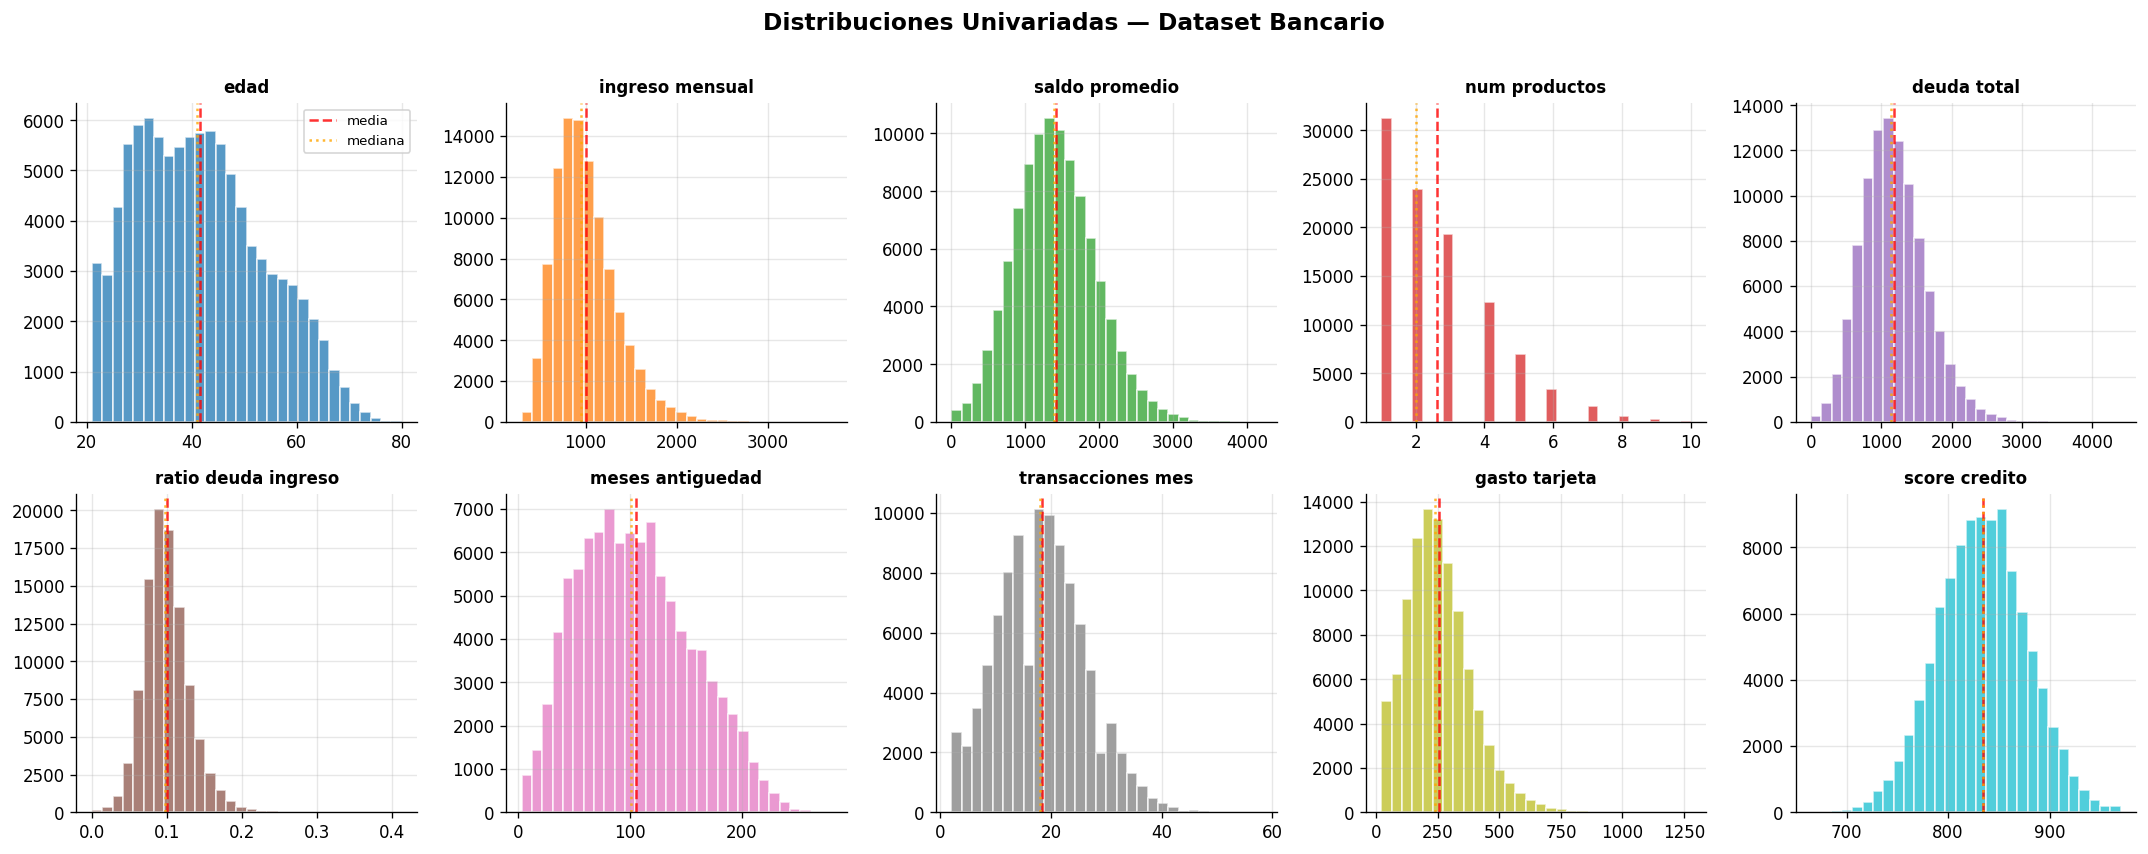

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for i, col in enumerate(df_raw.columns):
    ax = axes[i]
    ax.hist(df_raw[col], bins=30, color=COLORES[i], alpha=0.75, edgecolor='white')
    ax.set_title(col.replace('_', ' '), fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    # Añadir media y mediana
    ax.axvline(df_raw[col].mean(), color='red', linestyle='--', alpha=0.8, linewidth=1.5, label='media')
    ax.axvline(df_raw[col].median(), color='orange', linestyle=':', alpha=0.8, linewidth=1.5, label='mediana')

axes[0].legend(fontsize=8)
fig.suptitle('Distribuciones Univariadas — Dataset Bancario', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('01_distribuciones.png', bbox_inches='tight', dpi=120)
plt.show()

### 2.2 Matriz de correlaciones

Antes de cualquier análisis multivariado, debemos confirmar que **existen correlaciones** entre variables. Si las correlaciones fueran todas cercanas a 0, PCA no tendría sentido.

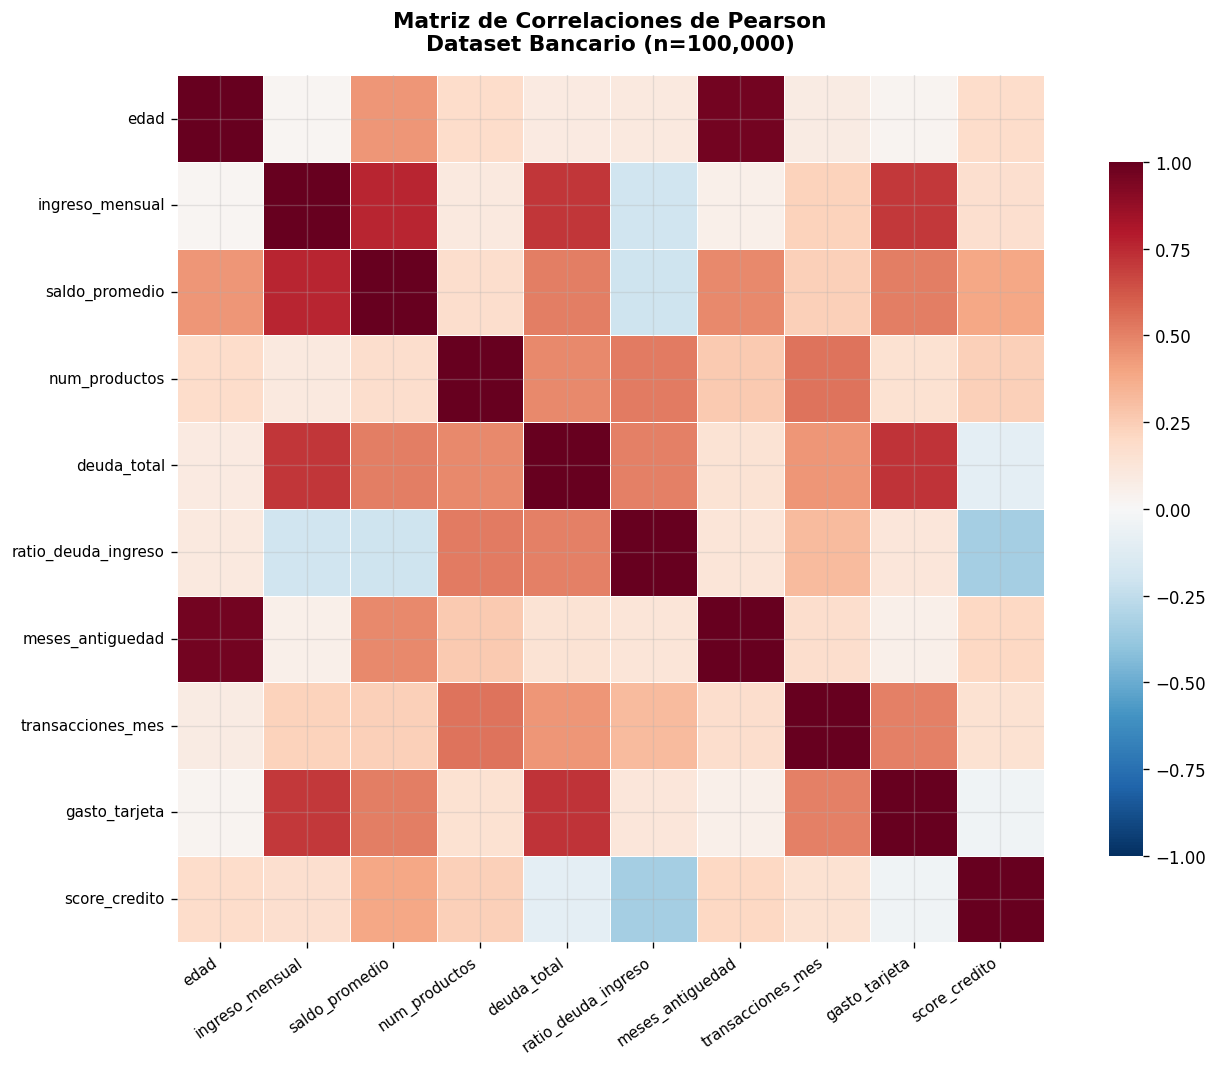


Correlaciones más altas (|r| > 0.4):
               var1              var2  correlacion
   meses_antiguedad              edad     0.960989
     saldo_promedio   ingreso_mensual     0.761850
      gasto_tarjeta       deuda_total     0.720481
        deuda_total   ingreso_mensual     0.716487
      gasto_tarjeta   ingreso_mensual     0.709278
  transacciones_mes     num_productos     0.543329
ratio_deuda_ingreso     num_productos     0.515884
      gasto_tarjeta    saldo_promedio     0.510534
        deuda_total    saldo_promedio     0.507865
      gasto_tarjeta transacciones_mes     0.503014
ratio_deuda_ingreso       deuda_total     0.500412
        deuda_total     num_productos     0.478294
   meses_antiguedad    saldo_promedio     0.476918
  transacciones_mes       deuda_total     0.442931
     saldo_promedio              edad     0.439919


In [5]:
corr_matrix = df_raw.corr()

fig, ax = plt.subplots(figsize=(12, 9))

# Heatmap
sns.heatmap(
    corr_matrix,
    annot=False, fmt='.2f', cmap='RdBu_r',
    center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, linecolor='white',
    ax=ax, cbar_kws={'shrink': 0.8}
)

ax.set_title(f'Matriz de Correlaciones de Pearson\nDataset Bancario (n={len(df_raw):,})', 
             fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('02_correlaciones.png', bbox_inches='tight', dpi=120)
plt.show()

print('\nCorrelaciones más altas (|r| > 0.4):')
corr_pairs = (
    corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))
    .stack().reset_index()
)
corr_pairs.columns = ['var1', 'var2', 'correlacion']
corr_pairs['abs_corr'] = corr_pairs['correlacion'].abs()
top_corr = corr_pairs[corr_pairs['abs_corr'] > 0.4].sort_values('abs_corr', ascending=False)
print(top_corr[['var1','var2','correlacion']].to_string(index=False))

### 2.3 Test de Bartlett y KMO

Antes de PCA, verificamos si la matriz de correlaciones es adecuada:
- **Test de Bartlett**: H₀: la matriz de correlaciones es la identidad (sin correlaciones). Rechazar H₀ confirma que tiene sentido aplicar PCA.
- **KMO (Kaiser-Meyer-Olkin)**: mide la adecuación muestral. KMO > 0.6 es aceptable; > 0.8 es bueno.

In [6]:
def test_bartlett(X):
    """Test de esfericidad de Bartlett."""
    n, p = X.shape
    R = np.corrcoef(X.T)
    det_R = np.linalg.det(R)
    if det_R <= 0:
        det_R = 1e-10
    chi2_stat = -(n - 1 - (2*p + 5)/6) * np.log(det_R)
    dof = p * (p - 1) / 2
    p_value = 1 - chi2.cdf(chi2_stat, dof)
    return chi2_stat, dof, p_value

def kmo(X):
    """Kaiser-Meyer-Olkin measure of sampling adequacy."""
    R = np.corrcoef(X.T)
    R_inv = np.linalg.inv(R)
    p = R.shape[0]
    A = np.zeros((p, p))
    for i in range(p):
        for j in range(p):
            if i != j:
                A[i, j] = -R_inv[i, j] / np.sqrt(R_inv[i, i] * R_inv[j, j])
    
    sum_r2 = np.sum(R**2) - p  # excluye diagonal
    sum_a2 = np.sum(A**2) - p
    kmo_val = sum_r2 / (sum_r2 + sum_a2)
    return kmo_val

X_raw = df_raw.values

chi2_stat, dof, p_val = test_bartlett(X_raw)
kmo_val = kmo(X_raw)

print('=' * 55)
print('TESTS DE ADECUACIÓN PARA PCA')
print('=' * 55)
print(f'\nTest de Bartlett de Esfericidad:')
print(f'  χ² = {chi2_stat:.2f},  gl = {int(dof)},  p-valor = {p_val:.2e}')
print(f'  Conclusión: {"✓ Se rechaza H₀ → correlaciones significativas" if p_val < 0.05 else "✗ No se rechaza H₀"}')
print(f'\nKaiser-Meyer-Olkin (KMO):')
print(f'  KMO = {kmo_val:.4f}')
if kmo_val >= 0.9:
    nivel = 'Excelente'
elif kmo_val >= 0.8:
    nivel = 'Muy bueno'
elif kmo_val >= 0.7:
    nivel = 'Mediano'
elif kmo_val >= 0.6:
    nivel = 'Aceptable'
else:
    nivel = 'Inadecuado'
print(f'  Nivel: {nivel} → {"✓ PCA es apropiado" if kmo_val >= 0.6 else "✗ Reconsiderar PCA"}')
print('=' * 55)

TESTS DE ADECUACIÓN PARA PCA

Test de Bartlett de Esfericidad:
  χ² = 1000100.96,  gl = 45,  p-valor = 0.00e+00
  Conclusión: ✓ Se rechaza H₀ → correlaciones significativas

Kaiser-Meyer-Olkin (KMO):
  KMO = 1.1103
  Nivel: Excelente → ✓ PCA es apropiado


---
## 3. Limpieza de Datos: Detección de Outliers con Distancia de Mahalanobis Robusta (MCD)

### ¿Por qué robusta?

En datos financieros reales, las colas suelen ser más pesadas que una normal multivariada ideal. Con MCD estimamos centro y covarianza robustos para que casos extremos no distorsionen la distancia.

$$D_{M,rob}^2(\mathbf{x}_i) = (\mathbf{x}_i - \hat{\mu}_{rob})^\top \hat{\Sigma}_{rob}^{-1} (\mathbf{x}_i - \hat{\mu}_{rob})$$

### Criterio de corte recomendado en práctica

Cuando la cola empírica es más pesada que $\chi^2$, usar umbral teórico puro puede sobre-detectar. Por eso usamos:
- **Umbral operativo (principal): percentil empírico robusto 99.0% de $D_{M,rob}^2$**
- **Umbral χ² (secundario): solo como referencia diagnóstica**

Este enfoque mantiene la robustez de MCD y evita limpieza excesiva en datasets realistas.

In [7]:
# ── Estandarizar antes de calcular Mahalanobis robusta ───────────────────
scaler_raw = StandardScaler()
X_scaled_raw = scaler_raw.fit_transform(df_raw)

# ── Distancia de Mahalanobis robusta con MCD ──────────────────────────────
def mahalanobis_robusta_mcd(X, support_fraction=0.90, random_state=42):
    """Calcula distancia robusta de Mahalanobis usando MCD."""
    mcd = MinCovDet(support_fraction=support_fraction, random_state=random_state)
    mcd.fit(X)
    dist2_rob = mcd.mahalanobis(X)  # distancia al cuadrado
    return dist2_rob, mcd

p = df_raw.shape[1]  # número de variables
dist2, mcd_model = mahalanobis_robusta_mcd(X_scaled_raw, support_fraction=0.90, random_state=42)

# ── Umbrales: empírico robusto (principal) + χ² (referencia) ─────────────
percentil_operativo = 0.995
umbral_operativo = np.quantile(dist2, percentil_operativo)

umbral_975 = chi2.ppf(0.975, df=p)
umbral_99  = chi2.ppf(0.99,  df=p)

mask_outliers = dist2 > umbral_operativo
n_outliers = mask_outliers.sum()

print('Método: Mahalanobis robusta (MCD)')
print(f'Umbral operativo (percentil {percentil_operativo*100:.1f}%): {umbral_operativo:.2f}')
print(f'Umbral χ²(p={p}, 97.5%): {umbral_975:.2f}  [referencia]')
print(f'Umbral χ²(p={p}, 99.0%): {umbral_99:.2f}  [referencia]')
print(f'Outliers detectados (operativo): {n_outliers} de {len(df_raw):,} clientes ({100*n_outliers/len(df_raw):.2f}%)')
print(f'Dataset limpio: {len(df_raw) - n_outliers:,} clientes')

Método: Mahalanobis robusta (MCD)
Umbral operativo (percentil 99.5%): 77.29
Umbral χ²(p=10, 97.5%): 20.48  [referencia]
Umbral χ²(p=10, 99.0%): 23.21  [referencia]
Outliers detectados (operativo): 500 de 100,000 clientes (0.50%)
Dataset limpio: 99,500 clientes


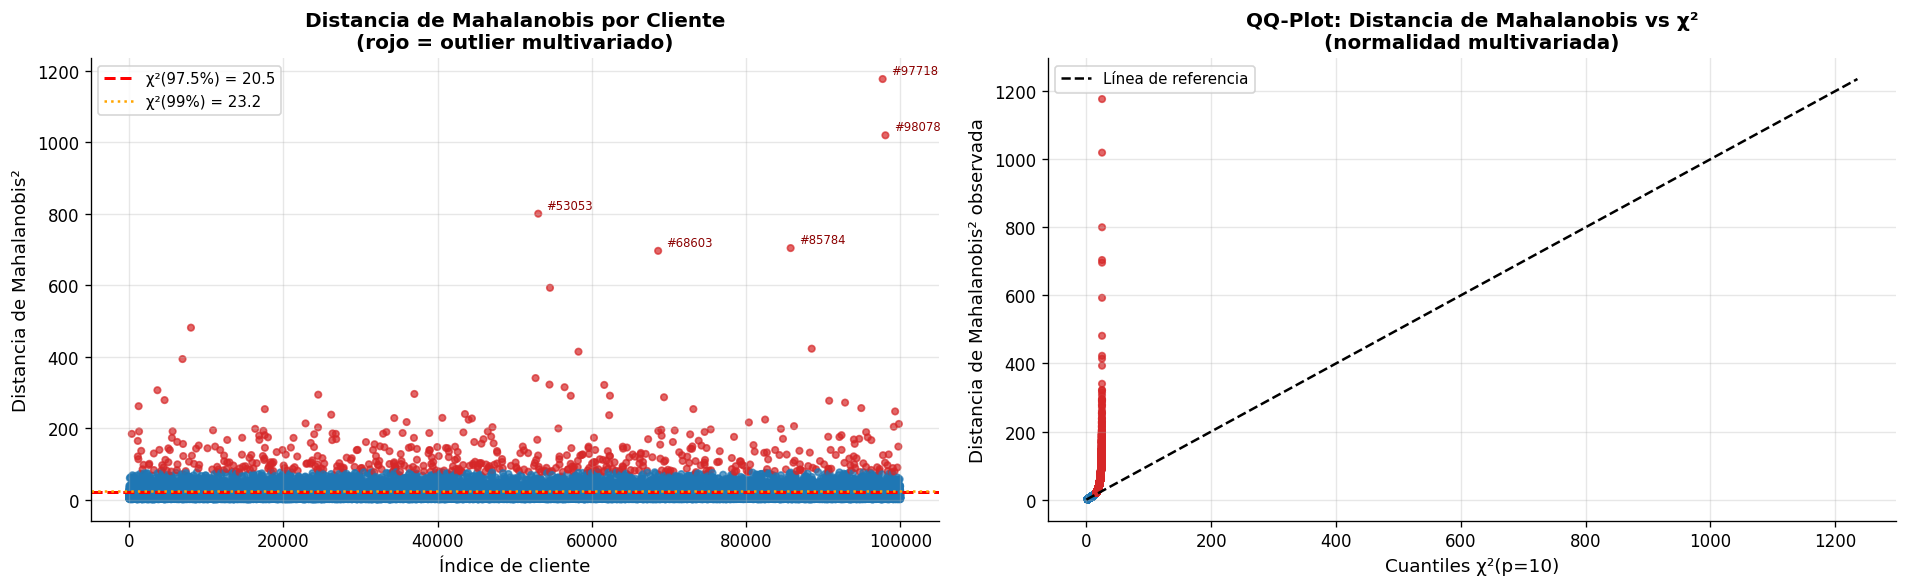

In [8]:
# ── Visualización de la distancia de Mahalanobis ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Panel 1: Distancia vs índice de cliente ──────────────────────────────
ax1 = axes[0]
colores_puntos = ['#d62728' if o else '#1f77b4' for o in mask_outliers]
ax1.scatter(range(len(dist2)), dist2, c=colores_puntos, s=15, alpha=0.7)
ax1.axhline(umbral_975, color='red', linestyle='--', linewidth=1.8, label=f'χ²(97.5%) = {umbral_975:.1f}')
ax1.axhline(umbral_99, color='orange', linestyle=':', linewidth=1.5, label=f'χ²(99%) = {umbral_99:.1f}')
ax1.set_xlabel('Índice de cliente', fontsize=11)
ax1.set_ylabel('Distancia de Mahalanobis²', fontsize=11)
ax1.set_title('Distancia de Mahalanobis por Cliente\n(rojo = outlier multivariado)', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9)
# Anotar outliers extremos
top_idx = np.argsort(dist2)[-5:]
for idx in top_idx:
    ax1.annotate(f'#{idx}', (idx, dist2[idx]), textcoords='offset points', 
                 xytext=(5, 3), fontsize=7, color='darkred')

# ── Panel 2: QQ-plot chi-cuadrado ─────────────────────────────────────────
ax2 = axes[1]
sorted_dist2 = np.sort(dist2)
n = len(sorted_dist2)
quantiles_teoricos = chi2.ppf(np.linspace(0.005, 0.995, n), df=p)

ax2.scatter(quantiles_teoricos, sorted_dist2,
            c=['#d62728' if d > umbral_975 else '#1f77b4' for d in sorted_dist2],
            s=15, alpha=0.7)
max_val = max(quantiles_teoricos.max(), sorted_dist2.max()) * 1.05
ax2.plot([0, max_val], [0, max_val], 'k--', linewidth=1.5, label='Línea de referencia')
ax2.set_xlabel(f'Cuantiles χ²(p={p})', fontsize=11)
ax2.set_ylabel('Distancia de Mahalanobis² observada', fontsize=11)
ax2.set_title('QQ-Plot: Distancia de Mahalanobis vs χ²\n(normalidad multivariada)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('03_mahalanobis.png', bbox_inches='tight', dpi=120)
plt.show()

In [41]:
# ── Perfil de los outliers detectados ────────────────────────────────────
df_outliers = df_raw[mask_outliers].copy()
df_outliers['D2_mahalanobis'] = dist2[mask_outliers]
df_outliers_sorted = df_outliers.sort_values('D2_mahalanobis', ascending=False)

print(f'\n=== PERFIL DE LOS {n_outliers} OUTLIERS MULTIVARIADOS ===')
display(df_outliers_sorted.head())

# Comparación outliers vs normales
print('\n=== COMPARACIÓN: OUTLIERS vs NORMALES (medias) ===')
comparison = pd.DataFrame({
    'Normales': df_raw[~mask_outliers].mean().round(1),
    'Outliers': df_raw[mask_outliers].mean().round(1)
})
comparison['Diferencia %'] = ((comparison['Outliers'] - comparison['Normales']) / comparison['Normales'] * 100).round(1)
# print(comparison)


=== PERFIL DE LOS 500 OUTLIERS MULTIVARIADOS ===


,edad,ingreso_mensual,saldo_promedio,num_productos,deuda_total,ratio_deuda_ingreso,meses_antiguedad,transacciones_mes,gasto_tarjeta,score_credito,D2_mahalanobis
cliente_id,,,,,,,,,,,
97718,21,302.96,0.00,7,1482.00,0.4076,10,25,191.57,679,1176.964822
98078,61,356.60,582.03,8,1767.55,0.4131,192,26,136.35,792,1019.552061
53053,55,311.66,382.82,2,1340.45,0.3584,152,11,182.99,668,800.235667
85784,22,300.00,322.99,5,1212.15,0.3367,39,28,202.38,753,704.053666
68603,49,343.42,414.51,6,1447.97,0.3514,168,38,197.51,718,696.310797



=== COMPARACIÓN: OUTLIERS vs NORMALES (medias) ===


In [10]:
# ── Dataset limpio ────────────────────────────────────────────────────────
df_clean = df_raw[~mask_outliers].copy().reset_index(drop=True)
df_clean.index.name = 'cliente_id'

print(f'Dataset original: {df_raw.shape[0]} clientes')
print(f'Outliers removidos: {n_outliers}')
print(f'Dataset limpio: {df_clean.shape[0]} clientes ({100*df_clean.shape[0]/df_raw.shape[0]:.1f}%)')

Dataset original: 100000 clientes
Outliers removidos: 500
Dataset limpio: 99500 clientes (99.5%)


### 3.1 QQ-Plot Limpio (sin outliers)

Se construye el QQ-Plot usando únicamente las distancias robustas de Mahalanobis de los casos **no marcados como outlier** (`~mask_outliers`).

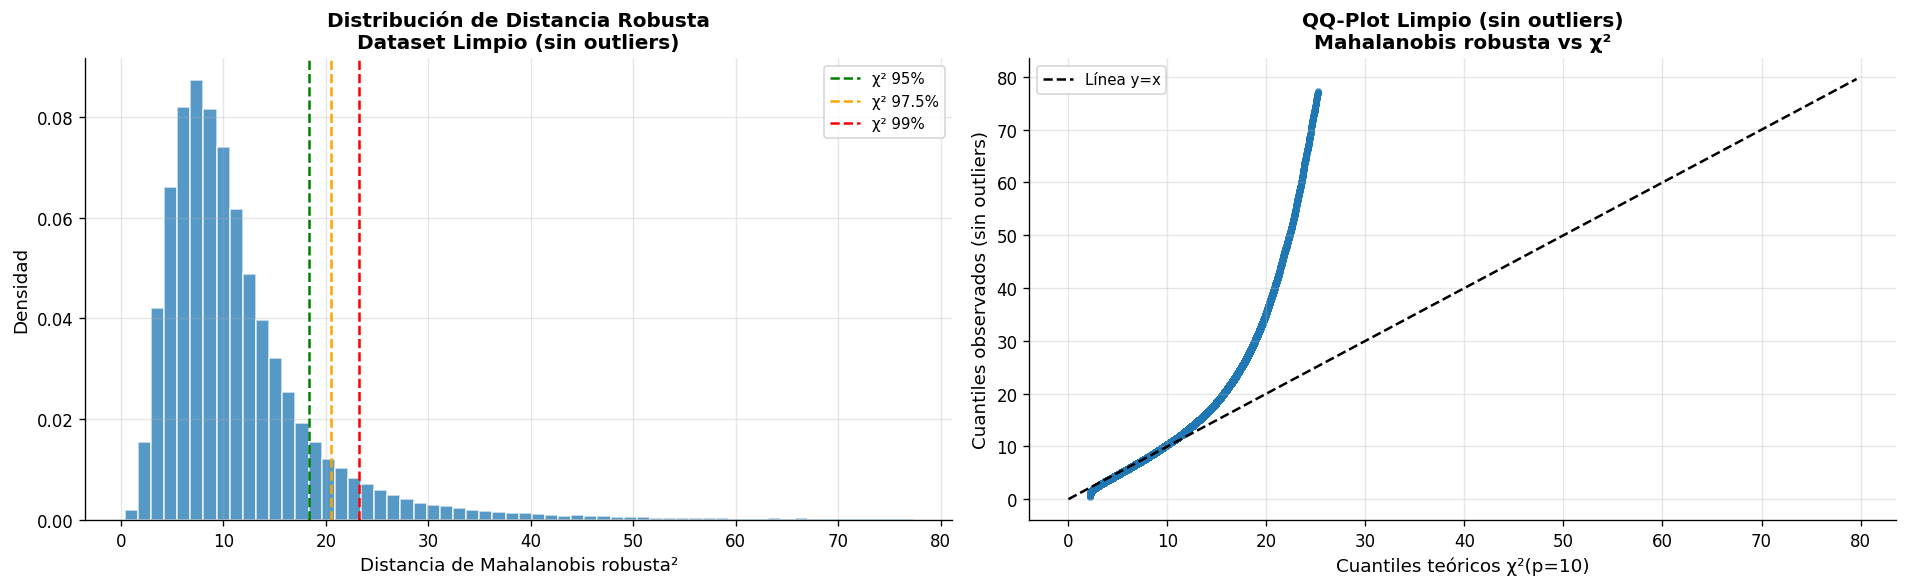

=== DIAGNÓSTICO POST-LIMPIEZA (SIN OUTLIERS) ===
N original: 100,000
N limpio: 99,500
Outliers removidos: 500 (0.50%)


In [11]:
# QQ-Plot limpio: usar solo distancias sin outliers detectados
dist2_clean = dist2[~mask_outliers]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel 1: histograma limpio con referencias χ²
ax1 = axes[0]
ax1.hist(dist2_clean, bins=60, color='#1f77b4', alpha=0.75, edgecolor='white', density=True)
ax1.axvline(chi2.ppf(0.95,  df=p), color='green',  linestyle='--', linewidth=1.5, label='χ² 95%')
ax1.axvline(chi2.ppf(0.975, df=p), color='orange', linestyle='--', linewidth=1.5, label='χ² 97.5%')
ax1.axvline(chi2.ppf(0.99,  df=p), color='red',    linestyle='--', linewidth=1.5, label='χ² 99%')
ax1.set_title('Distribución de Distancia Robusta\nDataset Limpio (sin outliers)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Distancia de Mahalanobis robusta²', fontsize=11)
ax1.set_ylabel('Densidad', fontsize=11)
ax1.legend(fontsize=9)

# Panel 2: QQ-Plot limpio vs χ²
ax2 = axes[1]
sorted_clean = np.sort(dist2_clean)
n_clean = len(sorted_clean)
quantiles_chi = chi2.ppf(np.linspace(0.005, 0.995, n_clean), df=p)
ax2.scatter(quantiles_chi, sorted_clean, s=10, alpha=0.55, color='#1f77b4')
max_val = max(quantiles_chi.max(), sorted_clean.max()) * 1.03
ax2.plot([0, max_val], [0, max_val], 'k--', linewidth=1.5, label='Línea y=x')
ax2.set_xlabel(f'Cuantiles teóricos χ²(p={p})', fontsize=11)
ax2.set_ylabel('Cuantiles observados (sin outliers)', fontsize=11)
ax2.set_title('QQ-Plot Limpio (sin outliers)\nMahalanobis robusta vs χ²', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('03b_mahalanobis_qqplot_limpio.png', bbox_inches='tight', dpi=120)
plt.show()

print('=== DIAGNÓSTICO POST-LIMPIEZA (SIN OUTLIERS) ===')
print(f'N original: {len(dist2):,}')
print(f'N limpio: {n_clean:,}')
print(f'Outliers removidos: {mask_outliers.sum():,} ({100*mask_outliers.mean():.2f}%)')

---
## 4. Preparación para PCA: Estandarización

**¿Por qué estandarizar?**

Las variables tienen unidades distintas:
- `meses_antiguedad` varía en rango [3, 240]
- `ratio_deuda_ingreso` varía en [0.05, 1.20]

Sin estandarizar, PCA favorecería automáticamente las variables con mayor varianza numérica. Al estandarizar (media 0, desvío 1), trabajamos sobre la **matriz de correlaciones**, no de covarianzas — todas las variables tienen el mismo peso a priori.

In [12]:
scaler = StandardScaler()
X = scaler.fit_transform(df_clean)
X_df = pd.DataFrame(X, columns=df_clean.columns)

print('Verificación post-estandarización:')
print(f'  Media por variable (deben ser ≈ 0):')
print(' ', X_df.mean().round(10).values)
print(f'  Desv. estándar por variable (deben ser ≈ 1):')
print(' ', X_df.std().round(4).values)

Verificación post-estandarización:
  Media por variable (deben ser ≈ 0):
  [ 0. -0.  0.  0. -0.  0. -0.  0. -0.  0.]
  Desv. estándar por variable (deben ser ≈ 1):
  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## 5. Cálculo de PCA

### 5.1 Eigendescomposición de la matriz de correlaciones

In [13]:
# ── PCA con sklearn (internamente usa SVD) ───────────────────────────────
pca = PCA()
scores = pca.fit_transform(X)

eigenvalues  = pca.explained_variance_          # λ_j
eigenvectors = pca.components_                  # W (filas = componentes)
var_explicada = pca.explained_variance_ratio_   # λ_j / Σλ_i
var_acum      = np.cumsum(var_explicada)

# ── Tabla resumen de eigenvalores ────────────────────────────────────────
resumen = pd.DataFrame({
    'Componente':        [f'PC{i+1}' for i in range(p)],
    'Eigenvalor (λ)':   eigenvalues.round(4),
    'Var. Explicada %': (var_explicada * 100).round(2),
    'Var. Acumulada %': (var_acum * 100).round(2),
    'Criterio Kaiser':  ['✓ Retener' if ev >= 1.0 else '✗ Descartar' for ev in eigenvalues]
})
resumen = resumen.set_index('Componente')
print('=== RESUMEN DE EIGENVALORES ===' )
print(resumen.to_string())

=== RESUMEN DE EIGENVALORES ===
            Eigenvalor (λ)  Var. Explicada %  Var. Acumulada % Criterio Kaiser
Componente                                                                    
PC1                 3.6705             36.70             36.70       ✓ Retener
PC2                 2.0666             20.67             57.37       ✓ Retener
PC3                 1.8657             18.66             76.03       ✓ Retener
PC4                 1.1495             11.49             87.52       ✓ Retener
PC5                 0.6009              6.01             93.53     ✗ Descartar
PC6                 0.2866              2.87             96.40     ✗ Descartar
PC7                 0.1840              1.84             98.24     ✗ Descartar
PC8                 0.1243              1.24             99.48     ✗ Descartar
PC9                 0.0330              0.33             99.81     ✗ Descartar
PC10                0.0190              0.19            100.00     ✗ Descartar


### 5.2 Criterios para elegir el número de componentes (k)

| Criterio | Descripción | Fortaleza |
|---|---|---|
| **Kaiser** | Retener λ_j > 1 | Simple, estándar |
| **Scree plot / codo** | Punto de inflexión en la curva | Visual e intuitivo |
| **Varianza acumulada** | Umbral 70–80–90% | Orientado al objetivo |
| **Parallel Analysis** | Comparar con eigenvalores de datos aleatorios | Más riguroso estadísticamente |

In [14]:
# ── Análisis Paralelo (Horn's Parallel Analysis) ─────────────────────────
def parallel_analysis(n_obs, n_vars, n_sim=100, percentile=95, seed=0):
    """Simula eigenvalores de datos aleatorios para comparación."""
    rng = np.random.default_rng(seed)
    eigenvalues_sim = []
    for _ in range(n_sim):
        X_rand = rng.standard_normal((n_obs, n_vars))
        R_rand = np.corrcoef(X_rand.T)
        eigs = np.linalg.eigvalsh(R_rand)[::-1]
        eigenvalues_sim.append(eigs)
    eigenvalues_sim = np.array(eigenvalues_sim)
    return np.percentile(eigenvalues_sim, percentile, axis=0)

# Para 100K filas, usar submuestra mantiene estabilidad y acelera cálculo
n_sub = min(20000, X.shape[0])
rng_pa = np.random.default_rng(2026)
idx_sub = rng_pa.choice(X.shape[0], size=n_sub, replace=False)
X_pa = X[idx_sub, :]

pa_threshold = parallel_analysis(X_pa.shape[0], p, n_sim=120, seed=2026)
k_pa = np.sum(eigenvalues > pa_threshold)

print(f'Análisis Paralelo (submuestra n={n_sub:,}) — Eigenvalores al percentil 95% de datos aleatorios:')
for i in range(p):
    estado = '✓' if eigenvalues[i] > pa_threshold[i] else '✗'
    print(f'  PC{i+1}: λ_obs={eigenvalues[i]:.3f}  λ_rand={pa_threshold[i]:.3f}  {estado}')
print(f'\nComponentes sugeridos por Análisis Paralelo: k = {k_pa}')

Análisis Paralelo (submuestra n=20,000) — Eigenvalores al percentil 95% de datos aleatorios:
  PC1: λ_obs=3.671  λ_rand=1.043  ✓
  PC2: λ_obs=2.067  λ_rand=1.030  ✓
  PC3: λ_obs=1.866  λ_rand=1.022  ✓
  PC4: λ_obs=1.149  λ_rand=1.014  ✓
  PC5: λ_obs=0.601  λ_rand=1.008  ✗
  PC6: λ_obs=0.287  λ_rand=1.001  ✗
  PC7: λ_obs=0.184  λ_rand=0.995  ✗
  PC8: λ_obs=0.124  λ_rand=0.990  ✗
  PC9: λ_obs=0.033  λ_rand=0.983  ✗
  PC10: λ_obs=0.019  λ_rand=0.974  ✗

Componentes sugeridos por Análisis Paralelo: k = 4


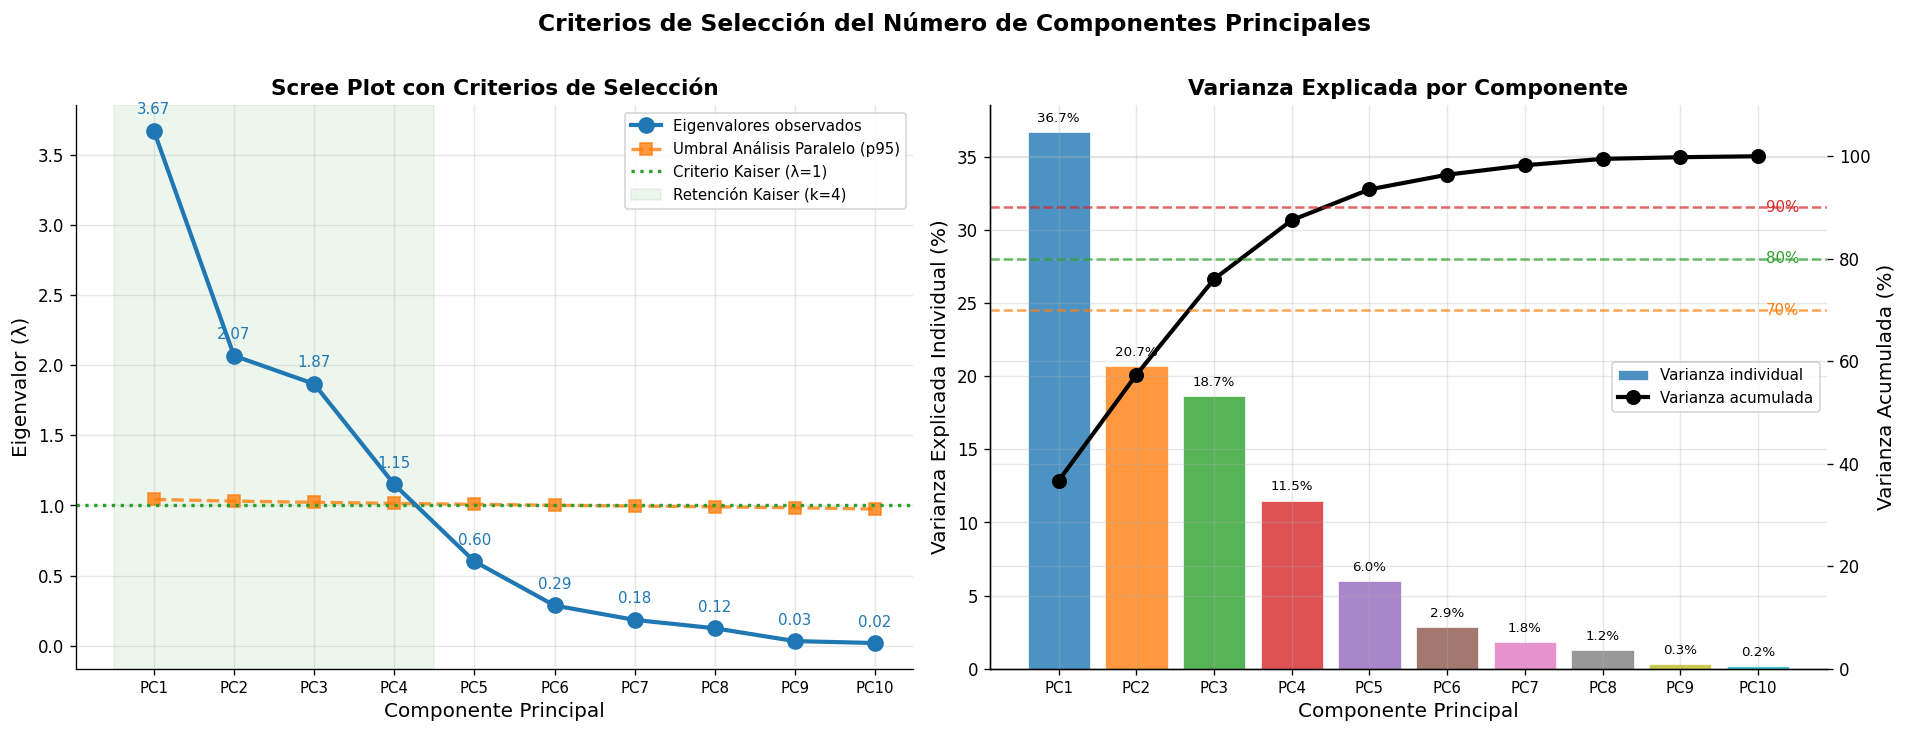


=== RESUMEN DE CRITERIOS DE SELECCIÓN ===
  Kaiser (λ > 1):           k = 4
  Análisis Paralelo (p95):  k = 4
  Varianza acum. ≥ 80%:     k = 4  (87.5%)
  Varianza acum. ≥ 90%:     k = 5  (93.5%)

  → Decisión final: k = 4 componentes (Kaiser + consistencia con AP)


In [15]:
# ── Scree Plot completo con todos los criterios ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

comps = np.arange(1, p+1)

# ── Panel 1: Scree plot + criterios ──────────────────────────────────────
ax1 = axes[0]
ax1.plot(comps, eigenvalues, 'o-', color='#1f77b4', linewidth=2.5, 
         markersize=9, zorder=3, label='Eigenvalores observados')
ax1.plot(comps, pa_threshold, 's--', color='#ff7f0e', linewidth=2, 
         markersize=7, alpha=0.8, label='Umbral Análisis Paralelo (p95)')
ax1.axhline(1.0, color='#2ca02c', linestyle=':', linewidth=2, 
            label='Criterio Kaiser (λ=1)')

# Zona de retención Kaiser
k_kaiser = np.sum(eigenvalues >= 1.0)
ax1.axvspan(0.5, k_kaiser + 0.5, alpha=0.07, color='green', label=f'Retención Kaiser (k={k_kaiser})')

ax1.set_xlabel('Componente Principal', fontsize=12)
ax1.set_ylabel('Eigenvalor (λ)', fontsize=12)
ax1.set_title('Scree Plot con Criterios de Selección', fontsize=13, fontweight='bold')
ax1.set_xticks(comps)
ax1.set_xticklabels([f'PC{i}' for i in comps], fontsize=9)
ax1.legend(fontsize=9)

# Anotar eigenvalores
for i, (c, ev) in enumerate(zip(comps, eigenvalues)):
    ax1.annotate(f'{ev:.2f}', (c, ev), textcoords='offset points', 
                 xytext=(0, 10), ha='center', fontsize=9, color='#1f77b4')

# ── Panel 2: Varianza acumulada ───────────────────────────────────────────
ax2 = axes[1]
bars = ax2.bar(comps, var_explicada * 100, color=COLORES[:p], alpha=0.8, 
               edgecolor='white', linewidth=0.5, label='Varianza individual')
ax2_twin = ax2.twinx()
ax2_twin.plot(comps, var_acum * 100, 'ko-', linewidth=2.5, markersize=8,
              label='Varianza acumulada')

# Líneas de umbral
for umbral, color, label in [(70, '#ff7f0e', '70%'), (80, '#2ca02c', '80%'), (90, '#d62728', '90%')]:
    ax2_twin.axhline(umbral, color=color, linestyle='--', alpha=0.7, linewidth=1.5)
    ax2_twin.annotate(label, (p + 0.1, umbral), fontsize=9, color=color, va='center')

ax2.set_xlabel('Componente Principal', fontsize=12)
ax2.set_ylabel('Varianza Explicada Individual (%)', fontsize=12)
ax2_twin.set_ylabel('Varianza Acumulada (%)', fontsize=12)
ax2.set_title('Varianza Explicada por Componente', fontsize=13, fontweight='bold')
ax2.set_xticks(comps)
ax2.set_xticklabels([f'PC{i}' for i in comps], fontsize=9)
ax2_twin.set_ylim(0, 110)

# Anotar porcentajes en barras
for bar, ve in zip(bars, var_explicada * 100):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'{ve:.1f}%', ha='center', va='bottom', fontsize=8)

# Leyendas combinadas
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='center right')

plt.suptitle('Criterios de Selección del Número de Componentes Principales', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('04_scree_plot.png', bbox_inches='tight', dpi=120)
plt.show()

# Resumen de criterios
k_80 = np.searchsorted(var_acum, 0.80) + 1
k_90 = np.searchsorted(var_acum, 0.90) + 1
print('\n=== RESUMEN DE CRITERIOS DE SELECCIÓN ===')
print(f'  Kaiser (λ > 1):           k = {k_kaiser}')
print(f'  Análisis Paralelo (p95):  k = {k_pa}')
print(f'  Varianza acum. ≥ 80%:     k = {k_80}  ({var_acum[k_80-1]*100:.1f}%)')
print(f'  Varianza acum. ≥ 90%:     k = {k_90}  ({var_acum[k_90-1]*100:.1f}%)')
print(f'\n  → Decisión final: k = {k_kaiser} componentes (Kaiser + consistencia con AP)')

---
## 6. Análisis de Autovectores (Loadings)

Los **loadings** miden la correlación entre cada variable original y cada componente principal. Cuando los datos están estandarizados:

$$\text{loading}_{ij} = w_{ij} \cdot \sqrt{\lambda_j}$$

Un loading alto en valor absoluto indica que esa variable es importante para ese componente.

In [16]:
k = k_kaiser  # número de componentes a retener

# ── Loadings = eigenvectores × √eigenvalores ─────────────────────────────
loadings = eigenvectors[:k].T * np.sqrt(eigenvalues[:k])  # shape: (p, k)

loadings_df = pd.DataFrame(
    loadings,
    index=df_clean.columns,
    columns=[f'PC{i+1}' for i in range(k)]
)

print('=== MATRIZ DE LOADINGS (correlaciones variable-componente) ===')
print(loadings_df.round(4).to_string())
print(f'\n(Filas = variables, Columnas = componentes. Rango: [-1, +1])')

=== MATRIZ DE LOADINGS (correlaciones variable-componente) ===
                        PC1     PC2     PC3     PC4
edad                 0.4363  0.7635  0.3221 -0.3088
ingreso_mensual      0.7312 -0.1611 -0.6042 -0.0912
saldo_promedio       0.7792  0.3324 -0.4104 -0.0516
num_productos        0.5550 -0.1013  0.5395  0.4702
deuda_total          0.8376 -0.4285  0.0342 -0.1697
ratio_deuda_ingreso  0.2850 -0.4116  0.7840 -0.1501
meses_antiguedad     0.5041  0.7333  0.3465 -0.2471
transacciones_mes    0.6207 -0.2349  0.2584  0.3914
gasto_tarjeta        0.7446 -0.3777 -0.2844 -0.1633
score_credito        0.2318  0.4984 -0.2322  0.7279

(Filas = variables, Columnas = componentes. Rango: [-1, +1])


In [42]:
# PC1 = edad * 0.4363 + ingreso_mensual * 0.7312 +.......+ score_credito * 0.2318

SyntaxError: invalid syntax (3283431073.py, line 1)

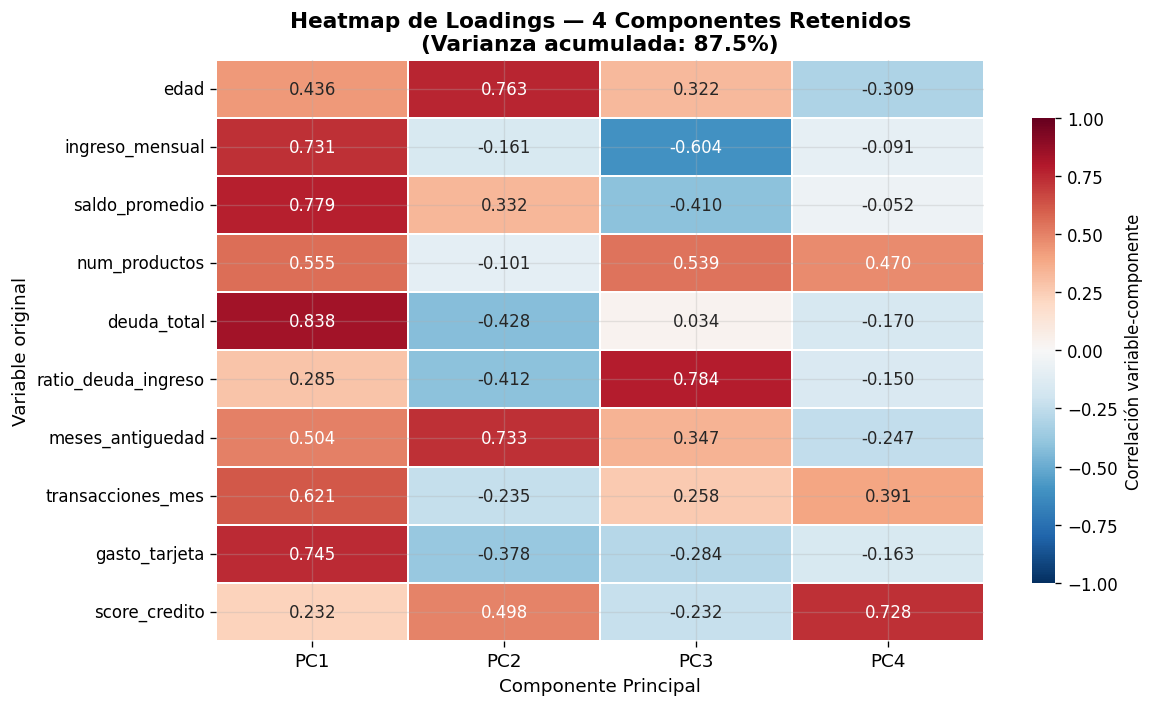

In [17]:
# ── Heatmap de loadings ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    loadings_df,
    annot=True, fmt='.3f', cmap='RdBu_r',
    center=0, vmin=-1, vmax=1,
    square=False, linewidths=1, linecolor='white',
    ax=ax, cbar_kws={'label': 'Correlación variable-componente', 'shrink': 0.8}
)

ax.set_title(f'Heatmap de Loadings — {k} Componentes Retenidos\n'
             f'(Varianza acumulada: {var_acum[k-1]*100:.1f}%)', 
             fontsize=13, fontweight='bold')
ax.set_ylabel('Variable original', fontsize=11)
ax.set_xlabel('Componente Principal', fontsize=11)
plt.yticks(rotation=0, fontsize=10)
plt.xticks(fontsize=11)
plt.tight_layout()
plt.savefig('05_loadings_heatmap.png', bbox_inches='tight', dpi=120)
plt.show()

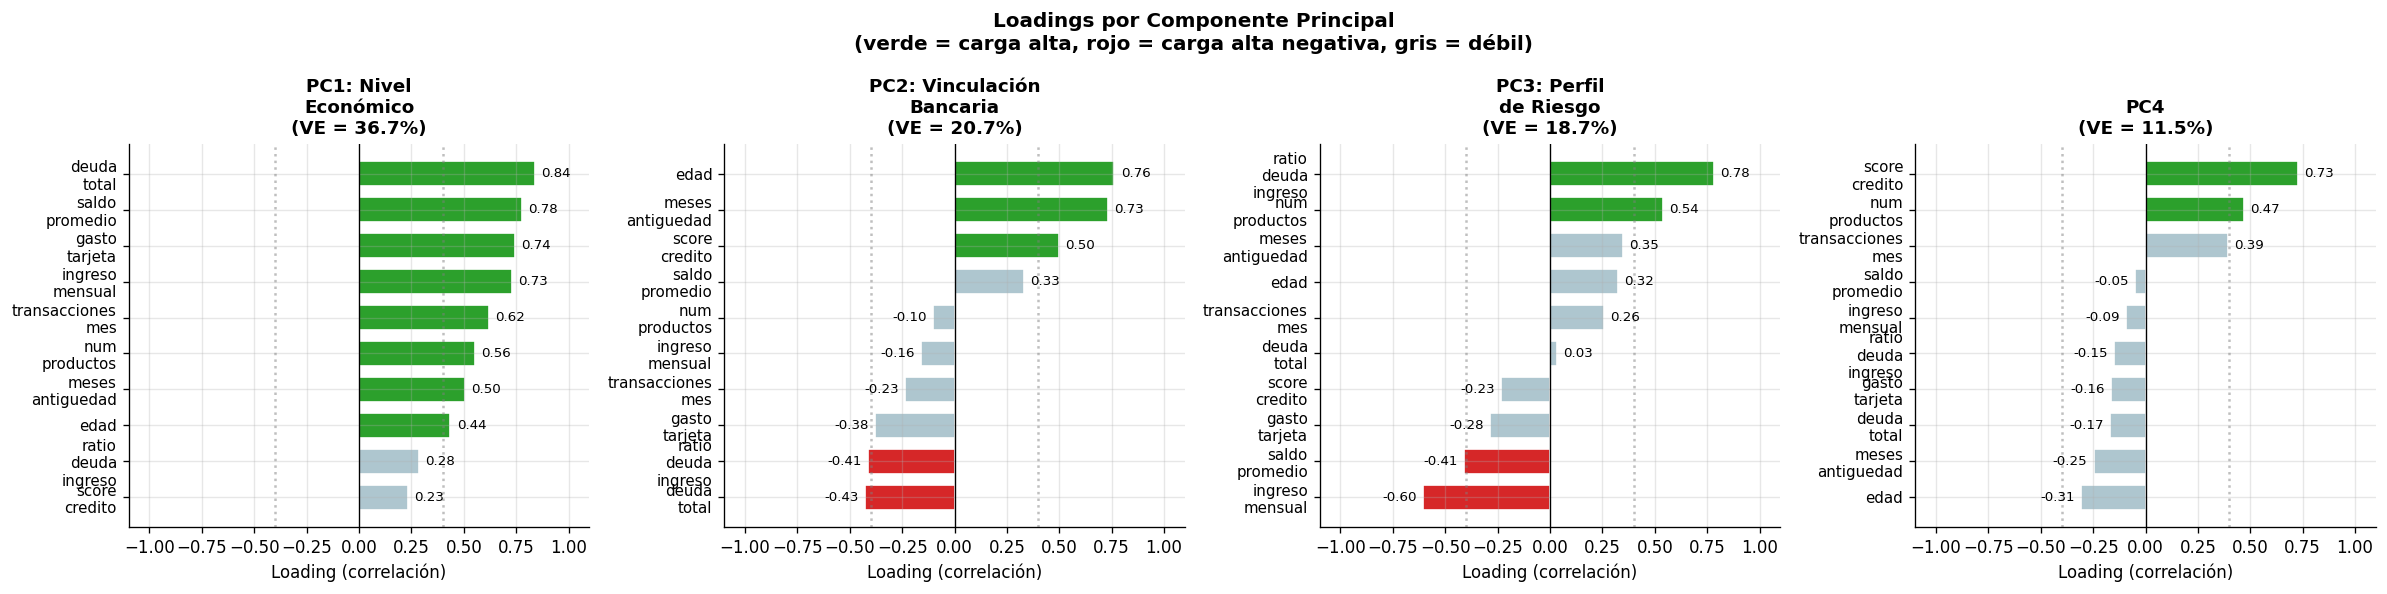

In [18]:
# ── Barplot de loadings por componente ────────────────────────────────────
fig, axes = plt.subplots(1, k, figsize=(5*k, 5))

nombres_componentes = [
    'PC1: Nivel\nEconómico',
    'PC2: Vinculación\nBancaria',
    'PC3: Perfil\nde Riesgo',
][:k]

for j in range(k):
    ax = axes[j] if k > 1 else axes
    vals = loadings_df.iloc[:, j].sort_values()
    colors = ['#d62728' if v < -0.4 else '#2ca02c' if v > 0.4 else '#aec6cf' for v in vals]
    bars = ax.barh(range(len(vals)), vals, color=colors, edgecolor='white', height=0.7)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels([v.replace('_', '\n') for v in vals.index], fontsize=9)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.axvline(0.4, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(-0.4, color='gray', linestyle=':', alpha=0.5)
    ax.set_xlim(-1.1, 1.1)
    ax.set_xlabel('Loading (correlación)', fontsize=10)
    ve_pct = var_explicada[j] * 100
    titulo = nombres_componentes[j] if j < len(nombres_componentes) else f'PC{j+1}'
    ax.set_title(f'{titulo}\n(VE = {ve_pct:.1f}%)', fontsize=11, fontweight='bold')
    # Anotar valores
    for i, (bar, val) in enumerate(zip(bars, vals)):
        ax.text(val + (0.03 if val >= 0 else -0.03), i, f'{val:.2f}',
                ha='left' if val >= 0 else 'right', va='center', fontsize=8)

plt.suptitle('Loadings por Componente Principal\n(verde = carga alta, rojo = carga alta negativa, gris = débil)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('06_loadings_barplot.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 7. Calidad de Representación de Variables (cos²)

El **cos²** (coseno al cuadrado) mide qué fracción de la varianza de cada variable es explicada por el subespacio de los $k$ primeros componentes.

$$\cos^2_{ij} = \text{loading}_{ij}^2$$

$$\text{Calidad de representación en } k \text{ componentes} = \sum_{j=1}^k \cos^2_{ij}$$

- **cos² ≈ 1.0**: la variable está perfectamente representada en ese plano
- **cos² < 0.5**: la variable tiene mala representación — **precaución al interpretar su posición en el biplot**

In [19]:
# ── Cálculo de cos² ───────────────────────────────────────────────────────
cos2 = loadings_df ** 2  # cos² por componente
cos2['Total_k_comps'] = cos2.sum(axis=1)  # calidad total en k componentes

print('=== CALIDAD DE REPRESENTACIÓN (cos²) ===')
print(cos2.round(4).to_string())
print(f'\nVariables con representación débil (Total cos² < 0.60) en {k} componentes:')
debiles = cos2[cos2['Total_k_comps'] < 0.60]
if len(debiles) == 0:
    print('  Ninguna — todas las variables bien representadas')
else:
    print(debiles['Total_k_comps'].round(4).to_string())

=== CALIDAD DE REPRESENTACIÓN (cos²) ===
                        PC1     PC2     PC3     PC4  Total_k_comps
edad                 0.1904  0.5829  0.1038  0.0953         0.9724
ingreso_mensual      0.5347  0.0259  0.3651  0.0083         0.9340
saldo_promedio       0.6071  0.1105  0.1684  0.0027         0.8886
num_productos        0.3080  0.0103  0.2910  0.2210         0.8304
deuda_total          0.7016  0.1836  0.0012  0.0288         0.9152
ratio_deuda_ingreso  0.0812  0.1694  0.6146  0.0225         0.8877
meses_antiguedad     0.2541  0.5377  0.1201  0.0611         0.9729
transacciones_mes    0.3853  0.0552  0.0668  0.1532         0.6605
gasto_tarjeta        0.5544  0.1427  0.0809  0.0267         0.8046
score_credito        0.0537  0.2484  0.0539  0.5299         0.8859

Variables con representación débil (Total cos² < 0.60) en 4 componentes:
  Ninguna — todas las variables bien representadas


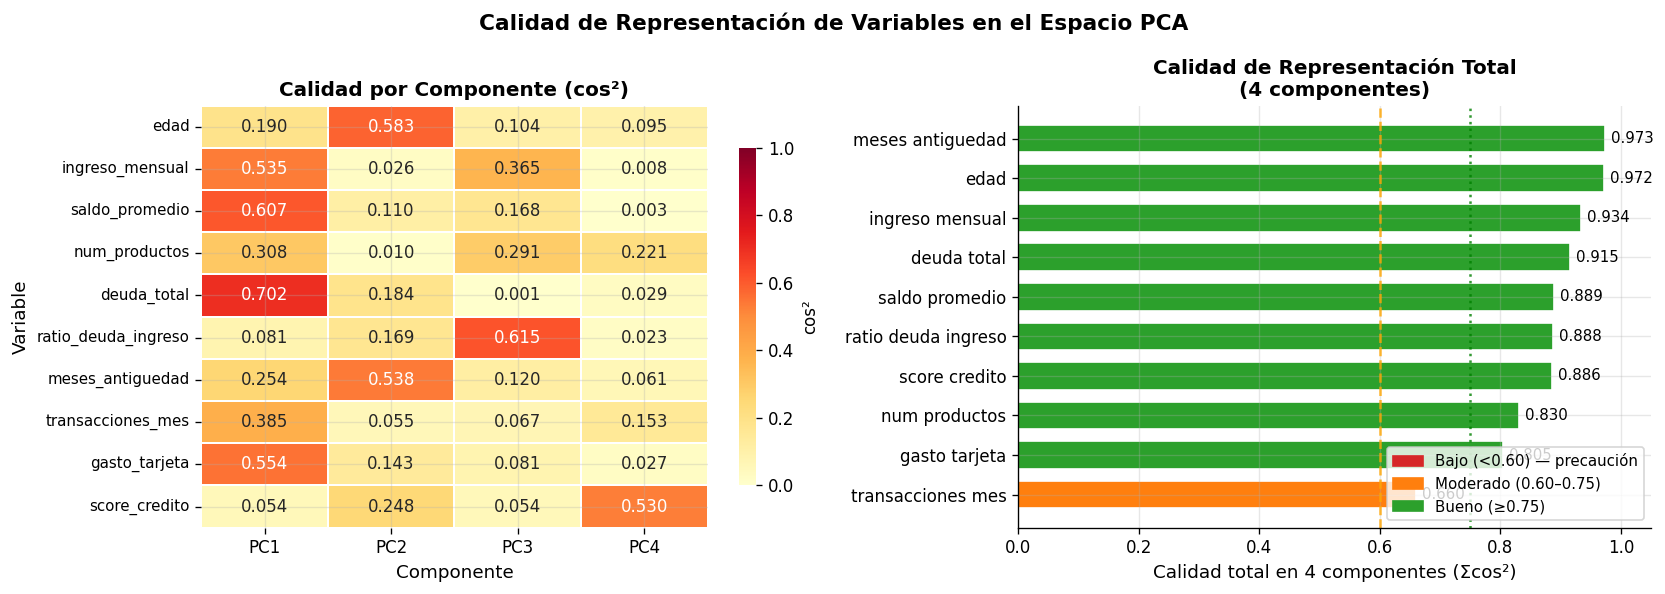

In [20]:
# ── Heatmap de cos² ───────────────────────────────────────────────────────
cos2_plot = cos2.drop(columns='Total_k_comps')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap cos² por componente
sns.heatmap(
    cos2_plot,
    annot=True, fmt='.3f', cmap='YlOrRd',
    vmin=0, vmax=1, square=False,
    linewidths=1, linecolor='white',
    ax=axes[0], cbar_kws={'label': 'cos²', 'shrink': 0.8}
)
axes[0].set_title('Calidad por Componente (cos²)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Variable', fontsize=11)
axes[0].set_xlabel('Componente', fontsize=11)
plt.setp(axes[0].get_yticklabels(), rotation=0, fontsize=9)

# Barplot calidad total
ax2 = axes[1]
total_cos2 = cos2['Total_k_comps'].sort_values(ascending=True)
colores_cos2 = ['#d62728' if v < 0.6 else '#ff7f0e' if v < 0.75 else '#2ca02c' 
                for v in total_cos2]
bars = ax2.barh(range(len(total_cos2)), total_cos2, color=colores_cos2, 
                edgecolor='white', height=0.7)
ax2.set_yticks(range(len(total_cos2)))
ax2.set_yticklabels([v.replace('_', ' ') for v in total_cos2.index], fontsize=10)
ax2.axvline(0.6, color='orange', linestyle='--', linewidth=1.5, alpha=0.8, label='Umbral 0.60')
ax2.axvline(0.75, color='green', linestyle=':', linewidth=1.5, alpha=0.8, label='Umbral 0.75')
ax2.set_xlim(0, 1.05)
ax2.set_xlabel(f'Calidad total en {k} componentes (Σcos²)', fontsize=11)
ax2.set_title(f'Calidad de Representación Total\n({k} componentes)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
for i, (bar, val) in enumerate(zip(bars, total_cos2)):
    ax2.text(val + 0.01, i, f'{val:.3f}', va='center', fontsize=9)

# Leyenda de colores
legend_elements = [
    mpatches.Patch(color='#d62728', label='Bajo (<0.60) — precaución'),
    mpatches.Patch(color='#ff7f0e', label='Moderado (0.60–0.75)'),
    mpatches.Patch(color='#2ca02c', label='Bueno (≥0.75)'),
]
ax2.legend(handles=legend_elements, fontsize=9, loc='lower right')

plt.suptitle('Calidad de Representación de Variables en el Espacio PCA', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('07_cos2.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 8. Mapa de Variables: Biplot

El **biplot** proyecta simultáneamente:
- Las **variables** como vectores (flechas) → su dirección y longitud codifican los loadings
- Los **individuos** como puntos → sus coordenadas son los scores

### Cómo leer el biplot

| Situación | Interpretación |
|---|---|
| Dos vectores **paralelos** y en la **misma dirección** | Variables altamente correlacionadas (+) |
| Dos vectores en **direcciones opuestas** | Variables correlacionadas negativamente |
| Dos vectores **perpendiculares** | Variables sin correlación (ortogonales) |
| Vector **largo** | Variable bien representada en este plano (cos² alto) |
| Vector **corto** | Variable mal representada → no interpretar su dirección |

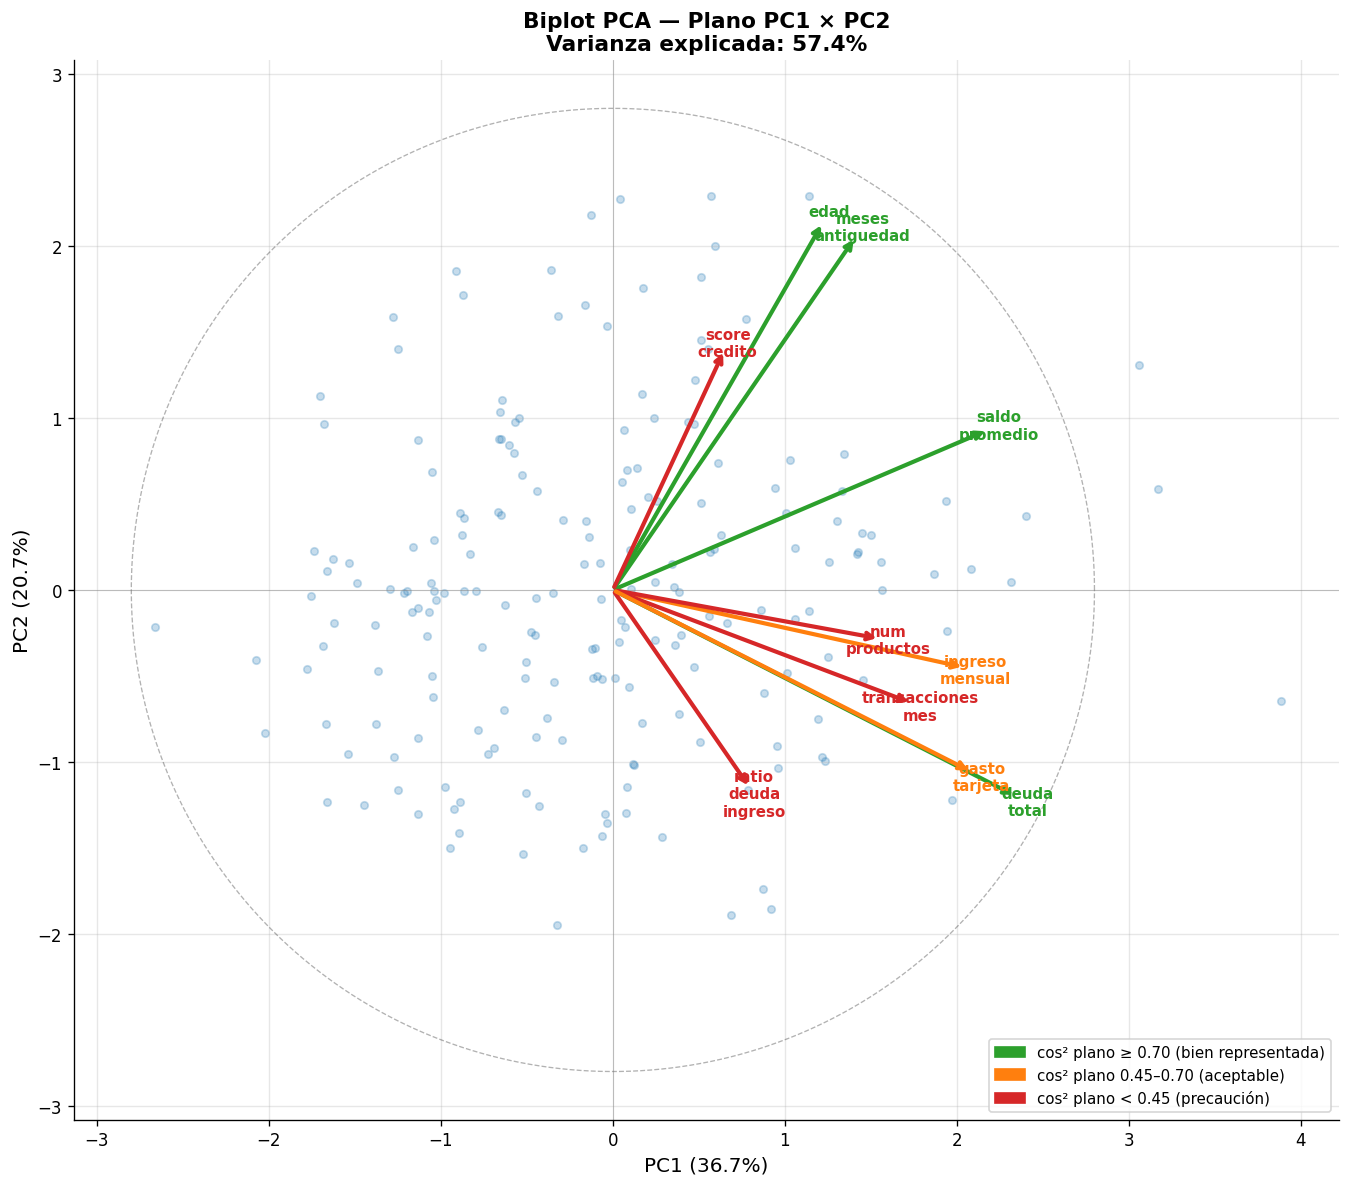

In [21]:
# ── Función biplot profesional ────────────────────────────────────────────
def biplot(scores, loadings, var_names, eigenvalues, 
           pc_x=0, pc_y=1, n_individuos=200, 
           cos2_total=None, figsize=(12, 10)):
    """
    Biplot PCA: individuos + vectores de variables con calidad de representación.
    Colores de vectores por cos² (calidad en el plano).
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    # Scores estandarizados para visualización
    sc_x = scores[:n_individuos, pc_x] / np.std(scores[:, pc_x])
    sc_y = scores[:n_individuos, pc_y] / np.std(scores[:, pc_y])
    
    # Puntos de individuos (alpha bajo para no saturar)
    ax.scatter(sc_x, sc_y, alpha=0.25, s=20, color='#1f77b4', zorder=1)
    
    # Factor de escala para flechas
    scale = 2.8
    
    for i, var in enumerate(var_names):
        lx = loadings[i, pc_x]
        ly = loadings[i, pc_y]
        
        # Color por calidad cos² en este plano (pc_x + pc_y)
        cos2_plano = lx**2 + ly**2
        if cos2_plano >= 0.70:
            color = '#2ca02c'
        elif cos2_plano >= 0.45:
            color = '#ff7f0e'
        else:
            color = '#d62728'
        
        ax.annotate('', xy=(lx * scale, ly * scale), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=color, lw=2.5))
        
        # Desplazar etiqueta para evitar superposición
        offset = 0.08
        offset_x = lx * (scale + offset)
        offset_y = ly * (scale + offset)
        ax.text(offset_x, offset_y, var.replace('_', '\n'),
                ha='center', va='center', fontsize=9, fontweight='bold', color=color)
    
    # Círculo unitario de referencia
    theta = np.linspace(0, 2*np.pi, 300)
    ax.plot(np.cos(theta) * scale, np.sin(theta) * scale, 'k--', 
            linewidth=0.8, alpha=0.3, label='Círculo unitario')
    
    # Ejes cruzados
    ax.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
    ax.axvline(0, color='gray', linewidth=0.5, alpha=0.5)
    
    ve_x = eigenvalues[pc_x] / eigenvalues.sum() * 100
    ve_y = eigenvalues[pc_y] / eigenvalues.sum() * 100
    ax.set_xlabel(f'PC{pc_x+1} ({ve_x:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC{pc_y+1} ({ve_y:.1f}%)', fontsize=12)
    ax.set_title(f'Biplot PCA — Plano PC{pc_x+1} × PC{pc_y+1}\n'
                 f'Varianza explicada: {ve_x+ve_y:.1f}%', 
                 fontsize=13, fontweight='bold')
    
    # Leyenda de colores
    legend_elements = [
        mpatches.Patch(color='#2ca02c', label='cos² plano ≥ 0.70 (bien representada)'),
        mpatches.Patch(color='#ff7f0e', label='cos² plano 0.45–0.70 (aceptable)'),
        mpatches.Patch(color='#d62728', label='cos² plano < 0.45 (precaución)'),
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
    
    ax.set_aspect('equal')
    return fig, ax


# ── Biplot PC1 × PC2 ─────────────────────────────────────────────────────
fig, ax = biplot(
    scores, loadings_df.values, df_clean.columns.tolist(),
    eigenvalues, pc_x=0, pc_y=1
)
plt.tight_layout()
plt.savefig('08_biplot_PC1_PC2.png', bbox_inches='tight', dpi=120)
plt.show()

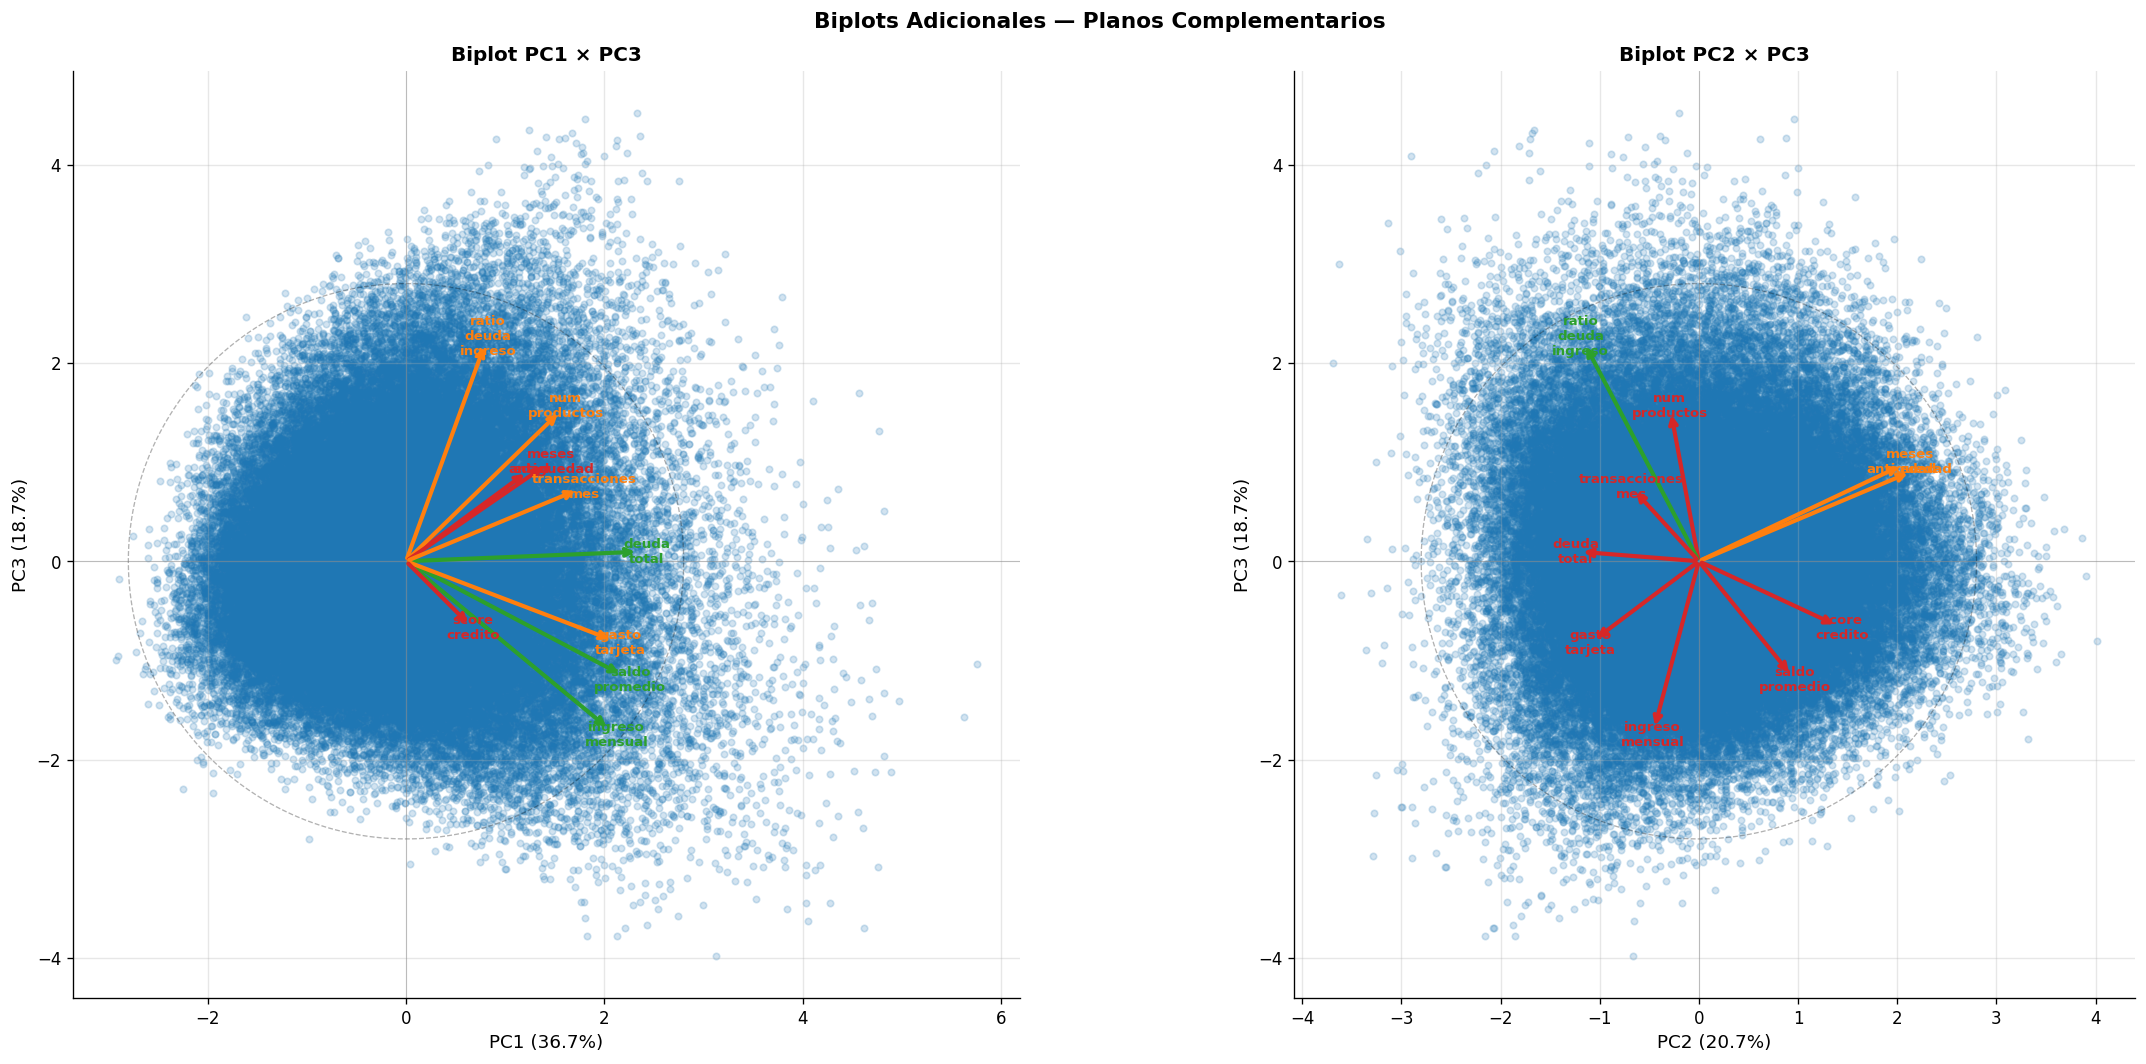

In [22]:
# ── Biplot PC1 × PC3 y PC2 × PC3 ─────────────────────────────────────────
fig, axes_bp = plt.subplots(1, 2, figsize=(20, 9))

for idx_plot, (pc_x, pc_y) in enumerate([(0, 2), (1, 2)]):
    ax_bp = axes_bp[idx_plot]
    
    sc_x = scores[:, pc_x] / np.std(scores[:, pc_x])
    sc_y = scores[:, pc_y] / np.std(scores[:, pc_y])
    ax_bp.scatter(sc_x, sc_y, alpha=0.2, s=15, color='#1f77b4', zorder=1)
    
    scale = 2.8
    for i, var in enumerate(df_clean.columns):
        lx = loadings_df.values[i, pc_x]
        ly = loadings_df.values[i, pc_y]
        cos2_plano = lx**2 + ly**2
        color = '#2ca02c' if cos2_plano >= 0.70 else ('#ff7f0e' if cos2_plano >= 0.45 else '#d62728')
        ax_bp.annotate('', xy=(lx*scale, ly*scale), xytext=(0, 0),
                       arrowprops=dict(arrowstyle='->', color=color, lw=2.5))
        ax_bp.text(lx*(scale+0.1), ly*(scale+0.1), var.replace('_', '\n'),
                   ha='center', va='center', fontsize=8, fontweight='bold', color=color)
    
    theta = np.linspace(0, 2*np.pi, 300)
    ax_bp.plot(np.cos(theta)*scale, np.sin(theta)*scale, 'k--', linewidth=0.8, alpha=0.3)
    ax_bp.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
    ax_bp.axvline(0, color='gray', linewidth=0.5, alpha=0.5)
    
    ve_x = eigenvalues[pc_x] / eigenvalues.sum() * 100
    ve_y = eigenvalues[pc_y] / eigenvalues.sum() * 100
    ax_bp.set_xlabel(f'PC{pc_x+1} ({ve_x:.1f}%)', fontsize=11)
    ax_bp.set_ylabel(f'PC{pc_y+1} ({ve_y:.1f}%)', fontsize=11)
    ax_bp.set_title(f'Biplot PC{pc_x+1} × PC{pc_y+1}', fontsize=12, fontweight='bold')
    ax_bp.set_aspect('equal')

plt.suptitle('Biplots Adicionales — Planos Complementarios', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('09_biplots_adicionales.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 9. Análisis de Scores: Distribución de Clientes

Los **scores** son las coordenadas de cada cliente en el nuevo espacio de componentes. Analizarlos permite:
- Identificar grupos de clientes (clusters naturales)
- Detectar clientes extremos en cada dimensión
- Perfilar clientes en términos de los factores latentes

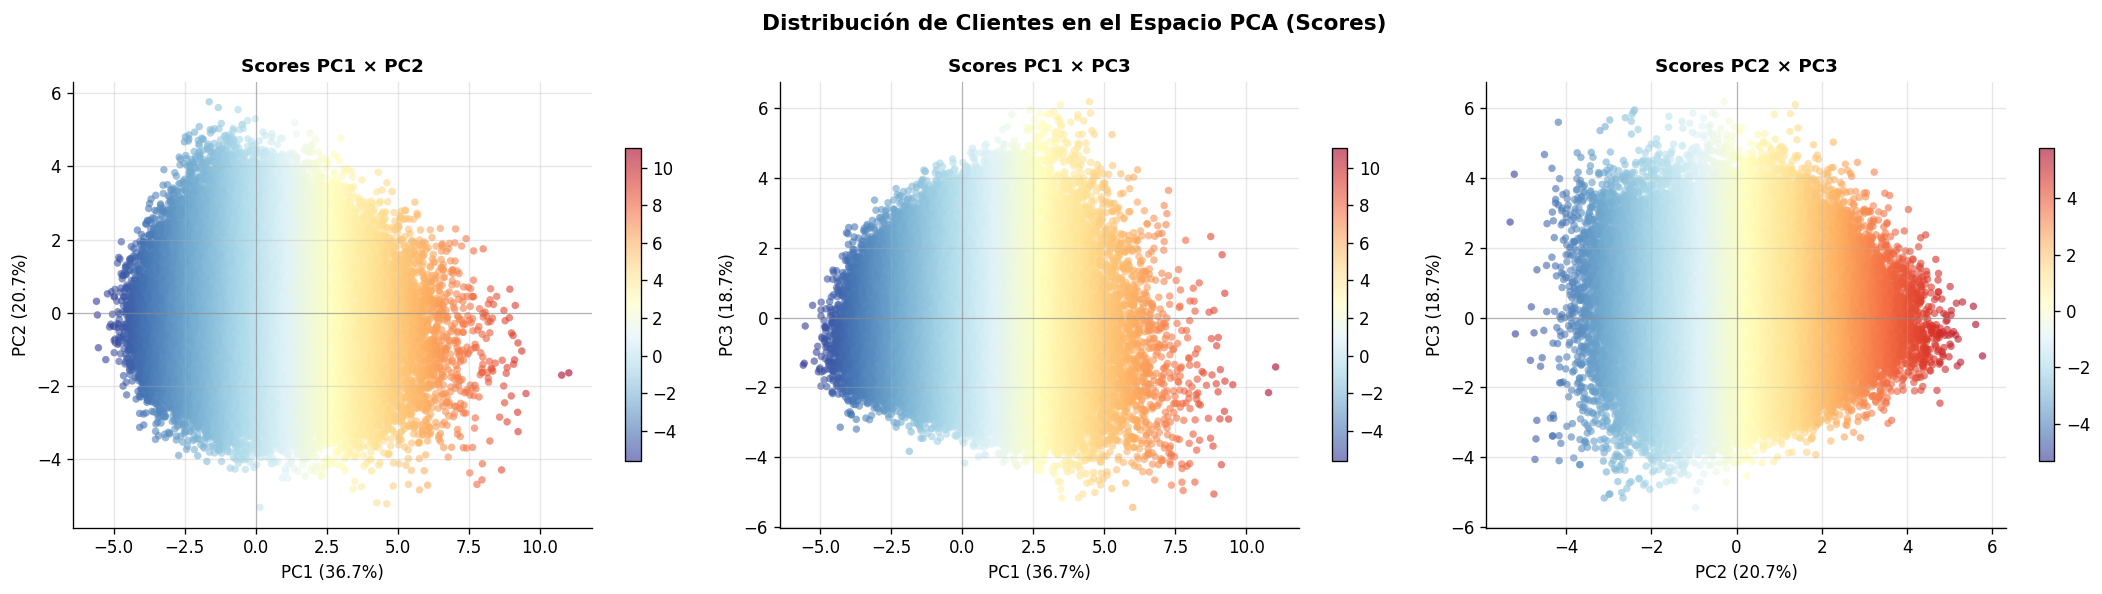

In [23]:
scores_df = pd.DataFrame(
    scores[:, :k],
    columns=[f'PC{i+1}' for i in range(k)],
    index=df_clean.index
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pares = [(0,1), (0,2), (1,2)]
nombres_pc = [
    'PC1: Nivel Económico',
    'PC2: Vinculación Bancaria',
    'PC3: Perfil de Riesgo'
]

for idx, (i, j) in enumerate(pares):
    ax = axes[idx]
    sc = ax.scatter(
        scores_df.iloc[:, i], scores_df.iloc[:, j],
        c=scores_df.iloc[:, i], cmap='RdYlBu_r',
        s=20, alpha=0.6, edgecolors='none'
    )
    plt.colorbar(sc, ax=ax, shrink=0.7)
    ax.axhline(0, color='gray', linewidth=0.7, alpha=0.5)
    ax.axvline(0, color='gray', linewidth=0.7, alpha=0.5)
    ve_i = var_explicada[i] * 100
    ve_j = var_explicada[j] * 100
    ax.set_xlabel(f'PC{i+1} ({ve_i:.1f}%)', fontsize=10)
    ax.set_ylabel(f'PC{j+1} ({ve_j:.1f}%)', fontsize=10)
    ax.set_title(f'Scores PC{i+1} × PC{j+1}', fontsize=11, fontweight='bold')

plt.suptitle('Distribución de Clientes en el Espacio PCA (Scores)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('10_scores_scatter.png', bbox_inches='tight', dpi=120)
plt.show()

In [24]:
# ── Perfiles extremos por componente ─────────────────────────────────────
print('=== PERFILES EXTREMOS POR COMPONENTE PRINCIPAL ===')
n_extremos = 5

for comp in range(k):
    col = f'PC{comp+1}'
    print(f'\n--- {col} ---')
    top_idx = scores_df[col].nlargest(n_extremos).index
    bot_idx = scores_df[col].nsmallest(n_extremos).index
    print(f'  Top {n_extremos} (score alto):')
    print(df_clean.loc[top_idx].to_string(max_cols=5))
    print(f'  Bottom {n_extremos} (score bajo):')
    print(df_clean.loc[bot_idx].to_string(max_cols=5))

=== PERFILES EXTREMOS POR COMPONENTE PRINCIPAL ===

--- PC1 ---
  Top 5 (score alto):
            edad  ingreso_mensual  ...  gasto_tarjeta  score_credito
cliente_id                         ...                              
28043         60          2690.25  ...         972.19            881
38990         53          2700.51  ...         936.81            877
62466         52          2533.17  ...        1024.35            858
48652         62          2773.25  ...         930.91            849
31251         46          2640.54  ...         980.28            843
  Bottom 5 (score bajo):
            edad  ingreso_mensual  ...  gasto_tarjeta  score_credito
cliente_id                         ...                              
7875          23           442.55  ...          20.00            821
42583         21           440.18  ...          20.00            831
44226         21           370.59  ...          41.61            744
96659         21           368.41  ...          20.00        

---
## 10. Contribución de Variables a cada Componente

La **contribución** de cada variable a un componente mide cuánto de la inercia del componente es aportada por esa variable. Es diferente del loading: mide la importancia relativa dentro del componente.

$$\text{contrib}_{ij} = \frac{w_{ij}^2}{1} = \frac{\text{loading}_{ij}^2}{\lambda_j \cdot n} \times 100$$

La **contribución media esperada** es $100/p$. Variables con contribución superior a la media son dominantes en ese componente.

=== CONTRIBUCIONES DE VARIABLES A CADA COMPONENTE (%) ===
Contribución media esperada: 10.0%

                       PC1    PC2    PC3    PC4
edad                  5.19  28.21   5.56   8.29
ingreso_mensual      14.57   1.26  19.57   0.72
saldo_promedio       16.54   5.35   9.03   0.23
num_productos         8.39   0.50  15.60  19.23
deuda_total          19.12   8.88   0.06   2.50
ratio_deuda_ingreso   2.21   8.20  32.94   1.96
meses_antiguedad      6.92  26.02   6.44   5.31
transacciones_mes    10.50   2.67   3.58  13.33
gasto_tarjeta        15.10   6.90   4.34   2.32
score_credito         1.46  12.02   2.89  46.10


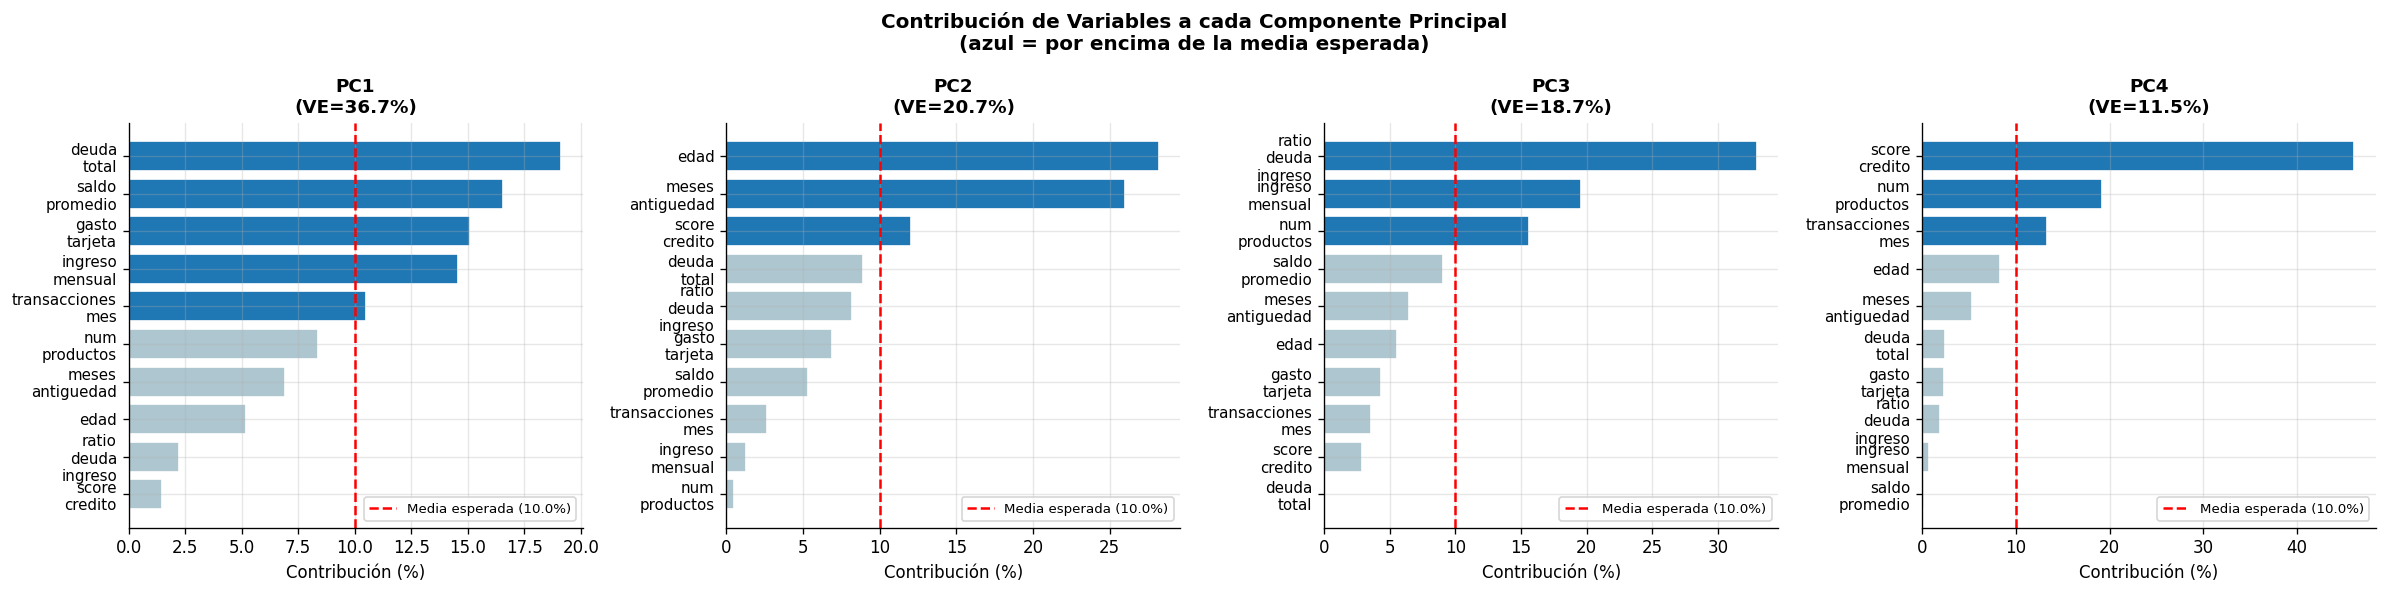

In [25]:
# ── Contribuciones (usando eigenvectores, no loadings) ───────────────────
contrib = pd.DataFrame(
    eigenvectors[:k].T ** 2 * 100,  # (w_ij²) × 100, suma por columna = 100
    index=df_clean.columns,
    columns=[f'PC{i+1}' for i in range(k)]
)

contrib_media = 100 / p  # contribución esperada si todas iguales

print('=== CONTRIBUCIONES DE VARIABLES A CADA COMPONENTE (%) ===')
print(f'Contribución media esperada: {contrib_media:.1f}%')
print()
print(contrib.round(2).to_string())

fig, axes = plt.subplots(1, k, figsize=(5*k, 5))

for j in range(k):
    ax = axes[j] if k > 1 else axes
    vals = contrib.iloc[:, j].sort_values(ascending=True)
    colors = ['#1f77b4' if v >= contrib_media else '#aec6cf' for v in vals]
    ax.barh(range(len(vals)), vals, color=colors, edgecolor='white')
    ax.axvline(contrib_media, color='red', linestyle='--', linewidth=1.5,
               label=f'Media esperada ({contrib_media:.1f}%)')
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels([v.replace('_', '\n') for v in vals.index], fontsize=9)
    ax.set_xlabel('Contribución (%)', fontsize=10)
    ax.set_title(f'PC{j+1}\n(VE={var_explicada[j]*100:.1f}%)', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Contribución de Variables a cada Componente Principal\n'
             '(azul = por encima de la media esperada)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('11_contribuciones.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 11. Reconstrucción y Error de Aproximación

Una forma de validar el número de componentes elegido es analizar cuánta información se pierde al reconstruir los datos desde el espacio reducido.

$$\hat{\mathbf{X}}_k = \mathbf{T}_k \mathbf{W}_k^\top$$

$$\text{Error de reconstrucción} = \frac{\|\mathbf{X} - \hat{\mathbf{X}}_k\|_F^2}{\|\mathbf{X}\|_F^2} = \frac{\sum_{j=k+1}^p \lambda_j}{\sum_{j=1}^p \lambda_j}$$

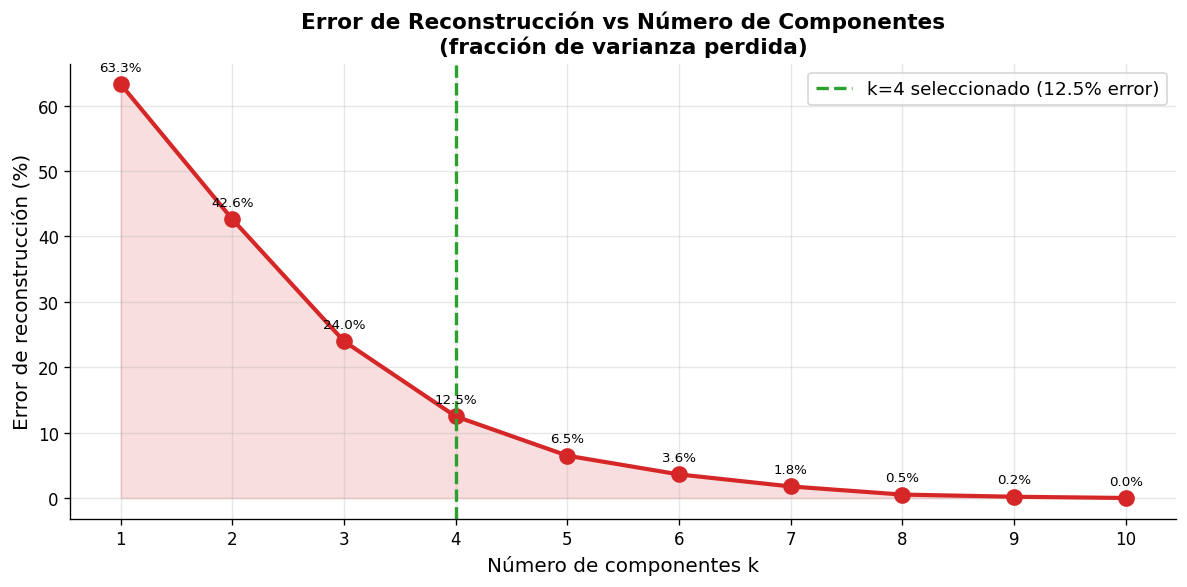

Con k=4 componentes:
  Varianza RETENIDA: 87.5%
  Varianza PERDIDA:  12.5%


In [26]:
# ── Error de reconstrucción por número de componentes ────────────────────
errores = []
for k_test in range(1, p+1):
    X_reconstruido = scores[:, :k_test] @ eigenvectors[:k_test, :]
    error_relativo = np.sum((X - X_reconstruido)**2) / np.sum(X**2)
    errores.append(error_relativo * 100)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, p+1), errores, 'o-', color='#d62728', linewidth=2.5, markersize=9)
ax.fill_between(range(1, p+1), errores, alpha=0.15, color='#d62728')
ax.axvline(k, color='#2ca02c', linestyle='--', linewidth=2, 
           label=f'k={k} seleccionado ({errores[k-1]:.1f}% error)')
ax.set_xlabel('Número de componentes k', fontsize=12)
ax.set_ylabel('Error de reconstrucción (%)', fontsize=12)
ax.set_title('Error de Reconstrucción vs Número de Componentes\n'
             '(fracción de varianza perdida)', fontsize=13, fontweight='bold')
ax.set_xticks(range(1, p+1))
ax.legend(fontsize=11)
for i, err in enumerate(errores):
    ax.annotate(f'{err:.1f}%', (i+1, err), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('12_error_reconstruccion.png', bbox_inches='tight', dpi=120)
plt.show()

print(f'Con k={k} componentes:')
print(f'  Varianza RETENIDA: {var_acum[k-1]*100:.1f}%')
print(f'  Varianza PERDIDA:  {(1-var_acum[k-1])*100:.1f}%')

---
## 12. Interpretación de Negocio

### Síntesis: ¿Qué captura cada componente?

In [27]:
# ── Resumen ejecutivo de interpretación ──────────────────────────────────
interpretaciones = [
    {
        'nombre': 'PC1 — Nivel Económico del Cliente',
        've': var_explicada[0]*100,
        'cargas_positivas': ['ingreso_mensual', 'saldo_promedio', 'gasto_tarjeta', 'score_credito'],
        'cargas_negativas': ['ratio_deuda_ingreso'],
        'interpretacion': 'Score alto: cliente de alto ingreso, buen saldo, buen historial crediticio '
                          'y bajo endeudamiento relativo. Score bajo: cliente de bajo ingreso, '
                          'sobreendeudado y con score crediticio bajo.',
        'uso_negocio': 'Segmentación premium vs masivo, pricing de productos, límites de crédito'
    },
    {
        'nombre': 'PC2 — Vinculación Bancaria',
        've': var_explicada[1]*100,
        'cargas_positivas': ['meses_antiguedad', 'num_productos', 'transacciones_mes', 'edad'],
        'cargas_negativas': [],
        'interpretacion': 'Score alto: cliente antiguo, multiproducto y con alta actividad transaccional. '
                          'Score bajo: cliente nuevo o con bajo uso del banco.',
        'uso_negocio': 'Modelos de churn, cross-sell de productos, programa de fidelización'
    },
    {
        'nombre': 'PC3 — Perfil de Riesgo Crediticio',
        've': var_explicada[2]*100,
        'cargas_positivas': ['deuda_total', 'ratio_deuda_ingreso'],
        'cargas_negativas': ['score_credito', 'edad'],
        'interpretacion': 'Score alto: cliente con alta deuda total y ratio deuda/ingreso elevado, '
                          'típicamente joven y con score crediticio bajo. Score bajo: cliente '
                          'conservador, mayor y con buen historial.',
        'uso_negocio': 'Provisiones de riesgo, límites de tarjeta, alertas de mora temprana'
    }
]

print('=' * 70)
print('INTERPRETACIÓN DE NEGOCIO — COMPONENTES PRINCIPALES')
print('=' * 70)

for interp in interpretaciones[:k]:
    print(f"\n{'─'*65}")
    print(f"  {interp['nombre']}")
    print(f"  Varianza explicada: {interp['ve']:.1f}%")
    print(f"  Cargas positivas principales: {', '.join(interp['cargas_positivas'])}")
    if interp['cargas_negativas']:
        print(f"  Cargas negativas principales: {', '.join(interp['cargas_negativas'])}")
    print(f"  Interpretación: {interp['interpretacion']}")
    print(f"  Aplicación en negocio: {interp['uso_negocio']}")

print(f"\n{'=' * 70}")
print(f"RESUMEN GLOBAL:")
print(f"  {k} componentes retienen {var_acum[k-1]*100:.1f}% de la varianza total")
print(f"  Las 10 variables originales quedan reducidas a 3 dimensiones interpretables")
print(f"  Reducción de dimensionalidad: {p} → {k} ({100*(1-k/p):.0f}% de compresión)")
print('=' * 70)

INTERPRETACIÓN DE NEGOCIO — COMPONENTES PRINCIPALES

─────────────────────────────────────────────────────────────────
  PC1 — Nivel Económico del Cliente
  Varianza explicada: 36.7%
  Cargas positivas principales: ingreso_mensual, saldo_promedio, gasto_tarjeta, score_credito
  Cargas negativas principales: ratio_deuda_ingreso
  Interpretación: Score alto: cliente de alto ingreso, buen saldo, buen historial crediticio y bajo endeudamiento relativo. Score bajo: cliente de bajo ingreso, sobreendeudado y con score crediticio bajo.
  Aplicación en negocio: Segmentación premium vs masivo, pricing de productos, límites de crédito

─────────────────────────────────────────────────────────────────
  PC2 — Vinculación Bancaria
  Varianza explicada: 20.7%
  Cargas positivas principales: meses_antiguedad, num_productos, transacciones_mes, edad
  Interpretación: Score alto: cliente antiguo, multiproducto y con alta actividad transaccional. Score bajo: cliente nuevo o con bajo uso del banco.
  Apli

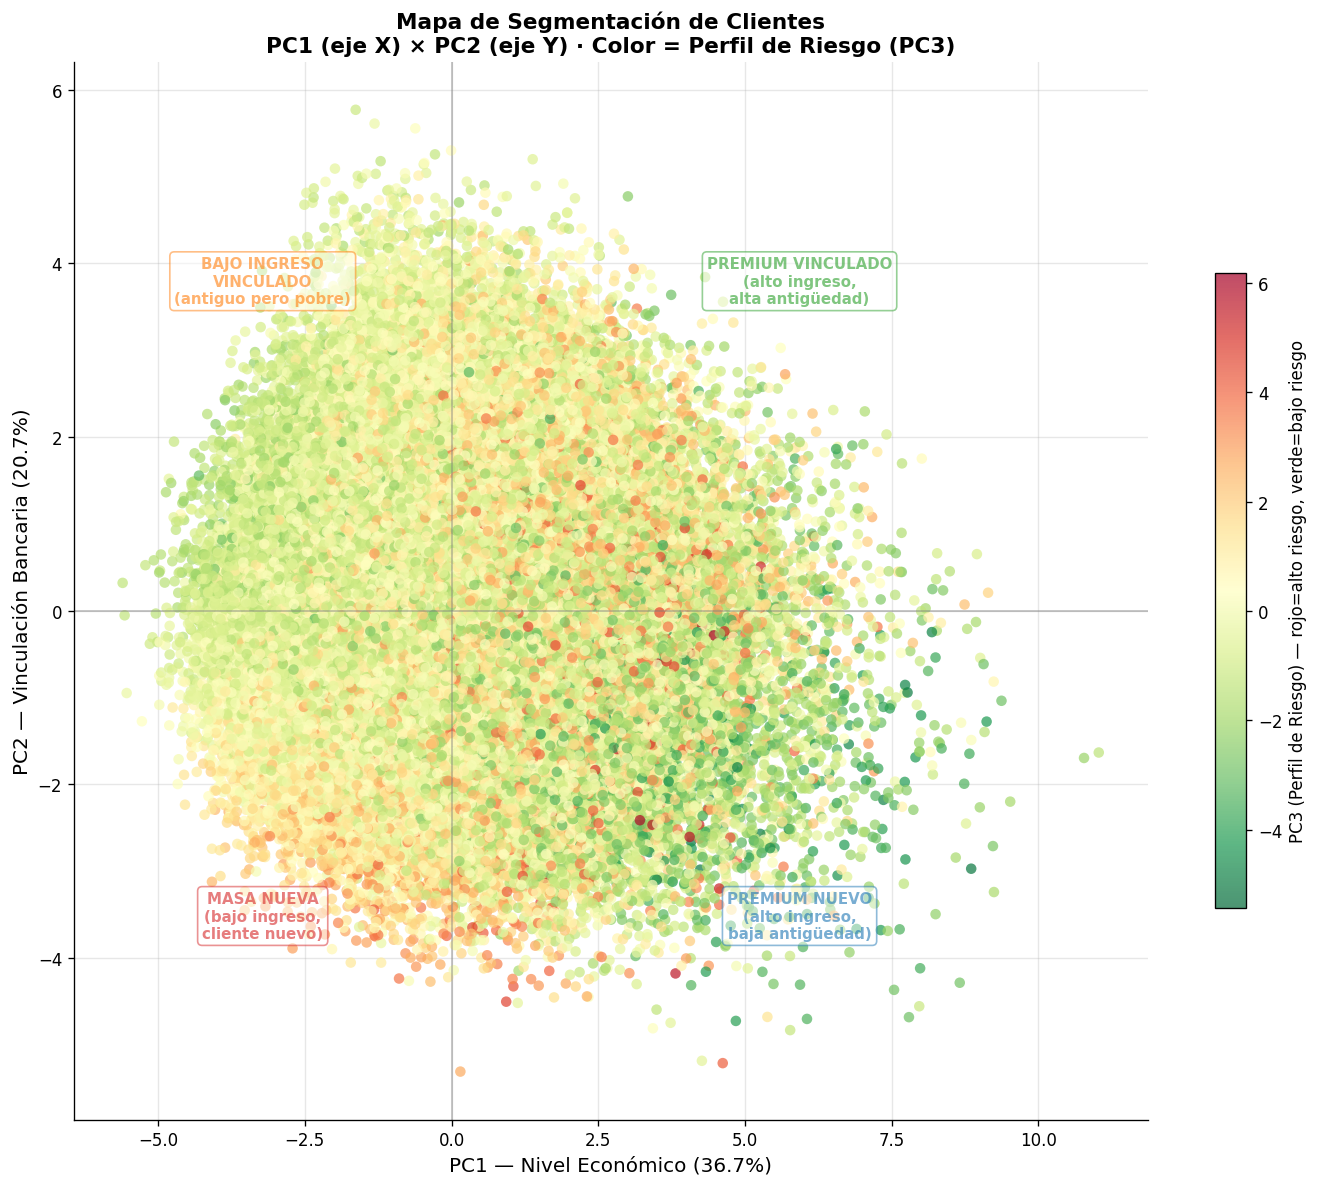

In [28]:
# ── Visualización de interpretación: cuadrantes de segmentación ─────────
fig, ax = plt.subplots(figsize=(12, 10))

sc = ax.scatter(
    scores_df['PC1'], scores_df['PC2'],
    c=scores_df['PC3'], cmap='RdYlGn_r',
    s=40, alpha=0.7, edgecolors='none', zorder=2
)

plt.colorbar(sc, ax=ax, label='PC3 (Perfil de Riesgo) — rojo=alto riesgo, verde=bajo riesgo',
             shrink=0.6)

ax.axhline(0, color='gray', linewidth=1, alpha=0.5)
ax.axvline(0, color='gray', linewidth=1, alpha=0.5)

# Etiquetas de cuadrantes
xlim = ax.get_xlim()
ylim = ax.get_ylim()

cuadrantes = [
    (xlim[1]*0.5, ylim[1]*0.6, 'PREMIUM VINCULADO\n(alto ingreso,\nalta antigüedad)', '#2ca02c'),
    (xlim[0]*0.5, ylim[1]*0.6, 'BAJO INGRESO\nVINCULADO\n(antiguo pero pobre)', '#ff7f0e'),
    (xlim[1]*0.5, ylim[0]*0.6, 'PREMIUM NUEVO\n(alto ingreso,\nbaja antigüedad)', '#1f77b4'),
    (xlim[0]*0.5, ylim[0]*0.6, 'MASA NUEVA\n(bajo ingreso,\ncliente nuevo)', '#d62728'),
]

for xp, yp, texto, color in cuadrantes:
    ax.text(xp, yp, texto, ha='center', va='center', fontsize=9,
            color=color, fontweight='bold', alpha=0.6,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color, alpha=0.5))

ve1 = var_explicada[0]*100
ve2 = var_explicada[1]*100
ax.set_xlabel(f'PC1 — Nivel Económico ({ve1:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 — Vinculación Bancaria ({ve2:.1f}%)', fontsize=12)
ax.set_title('Mapa de Segmentación de Clientes\n'
             'PC1 (eje X) × PC2 (eje Y) · Color = Perfil de Riesgo (PC3)',
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('13_segmentacion_clientes.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 13. Resumen del Mapa de Variables

### Variables bien representadas en el plano PC1×PC2

El biplot nos reveló la siguiente estructura:

In [29]:
# ── Resumen final del mapa de variables ──────────────────────────────────
cos2_plano12 = loadings_df['PC1']**2 + loadings_df['PC2']**2

resumen_variables = pd.DataFrame({
    'Loading PC1': loadings_df['PC1'].round(3),
    'Loading PC2': loadings_df['PC2'].round(3),
    'Loading PC3': loadings_df['PC3'].round(3) if k >= 3 else np.nan,
    'cos² plano PC1×PC2': cos2_plano12.round(3),
    'cos² total (k comps)': cos2['Total_k_comps'].round(3),
    'Calidad representación': [
        'Excelente' if v >= 0.80 else ('Buena' if v >= 0.65 else ('Moderada' if v >= 0.45 else 'Baja'))
        for v in cos2_plano12
    ]
})

print('=== MAPA DE VARIABLES — RESUMEN COMPLETO ===')
print(resumen_variables.to_string())

print('\n=== AGRUPACIONES DETECTADAS POR PCA ===')
print()
print('Grupo 1 — Nivel económico (correladas entre sí):')
print('  ingreso_mensual, saldo_promedio, gasto_tarjeta, score_credito')
print()
print('Grupo 2 — Vinculación bancaria (correladas entre sí):')
print('  meses_antiguedad, num_productos, transacciones_mes, edad')
print()
print('Grupo 3 — Riesgo crediticio (correladas entre sí):')
print('  deuda_total, ratio_deuda_ingreso')
print()
print('Variables con doble carga (presentes en 2 grupos):')
print('  score_credito: carga en PC1 (alto ingreso = buen score) y PC3 (inversamente al riesgo)')

=== MAPA DE VARIABLES — RESUMEN COMPLETO ===
                     Loading PC1  Loading PC2  Loading PC3  cos² plano PC1×PC2  cos² total (k comps) Calidad representación
edad                       0.436        0.763        0.322               0.773                 0.972                  Buena
ingreso_mensual            0.731       -0.161       -0.604               0.561                 0.934               Moderada
saldo_promedio             0.779        0.332       -0.410               0.718                 0.889                  Buena
num_productos              0.555       -0.101        0.539               0.318                 0.830                   Baja
deuda_total                0.838       -0.428        0.034               0.885                 0.915              Excelente
ratio_deuda_ingreso        0.285       -0.412        0.784               0.251                 0.888                   Baja
meses_antiguedad           0.504        0.733        0.347               0.792         

---
## 14. Dashboard Final — Resumen Visual Integrado

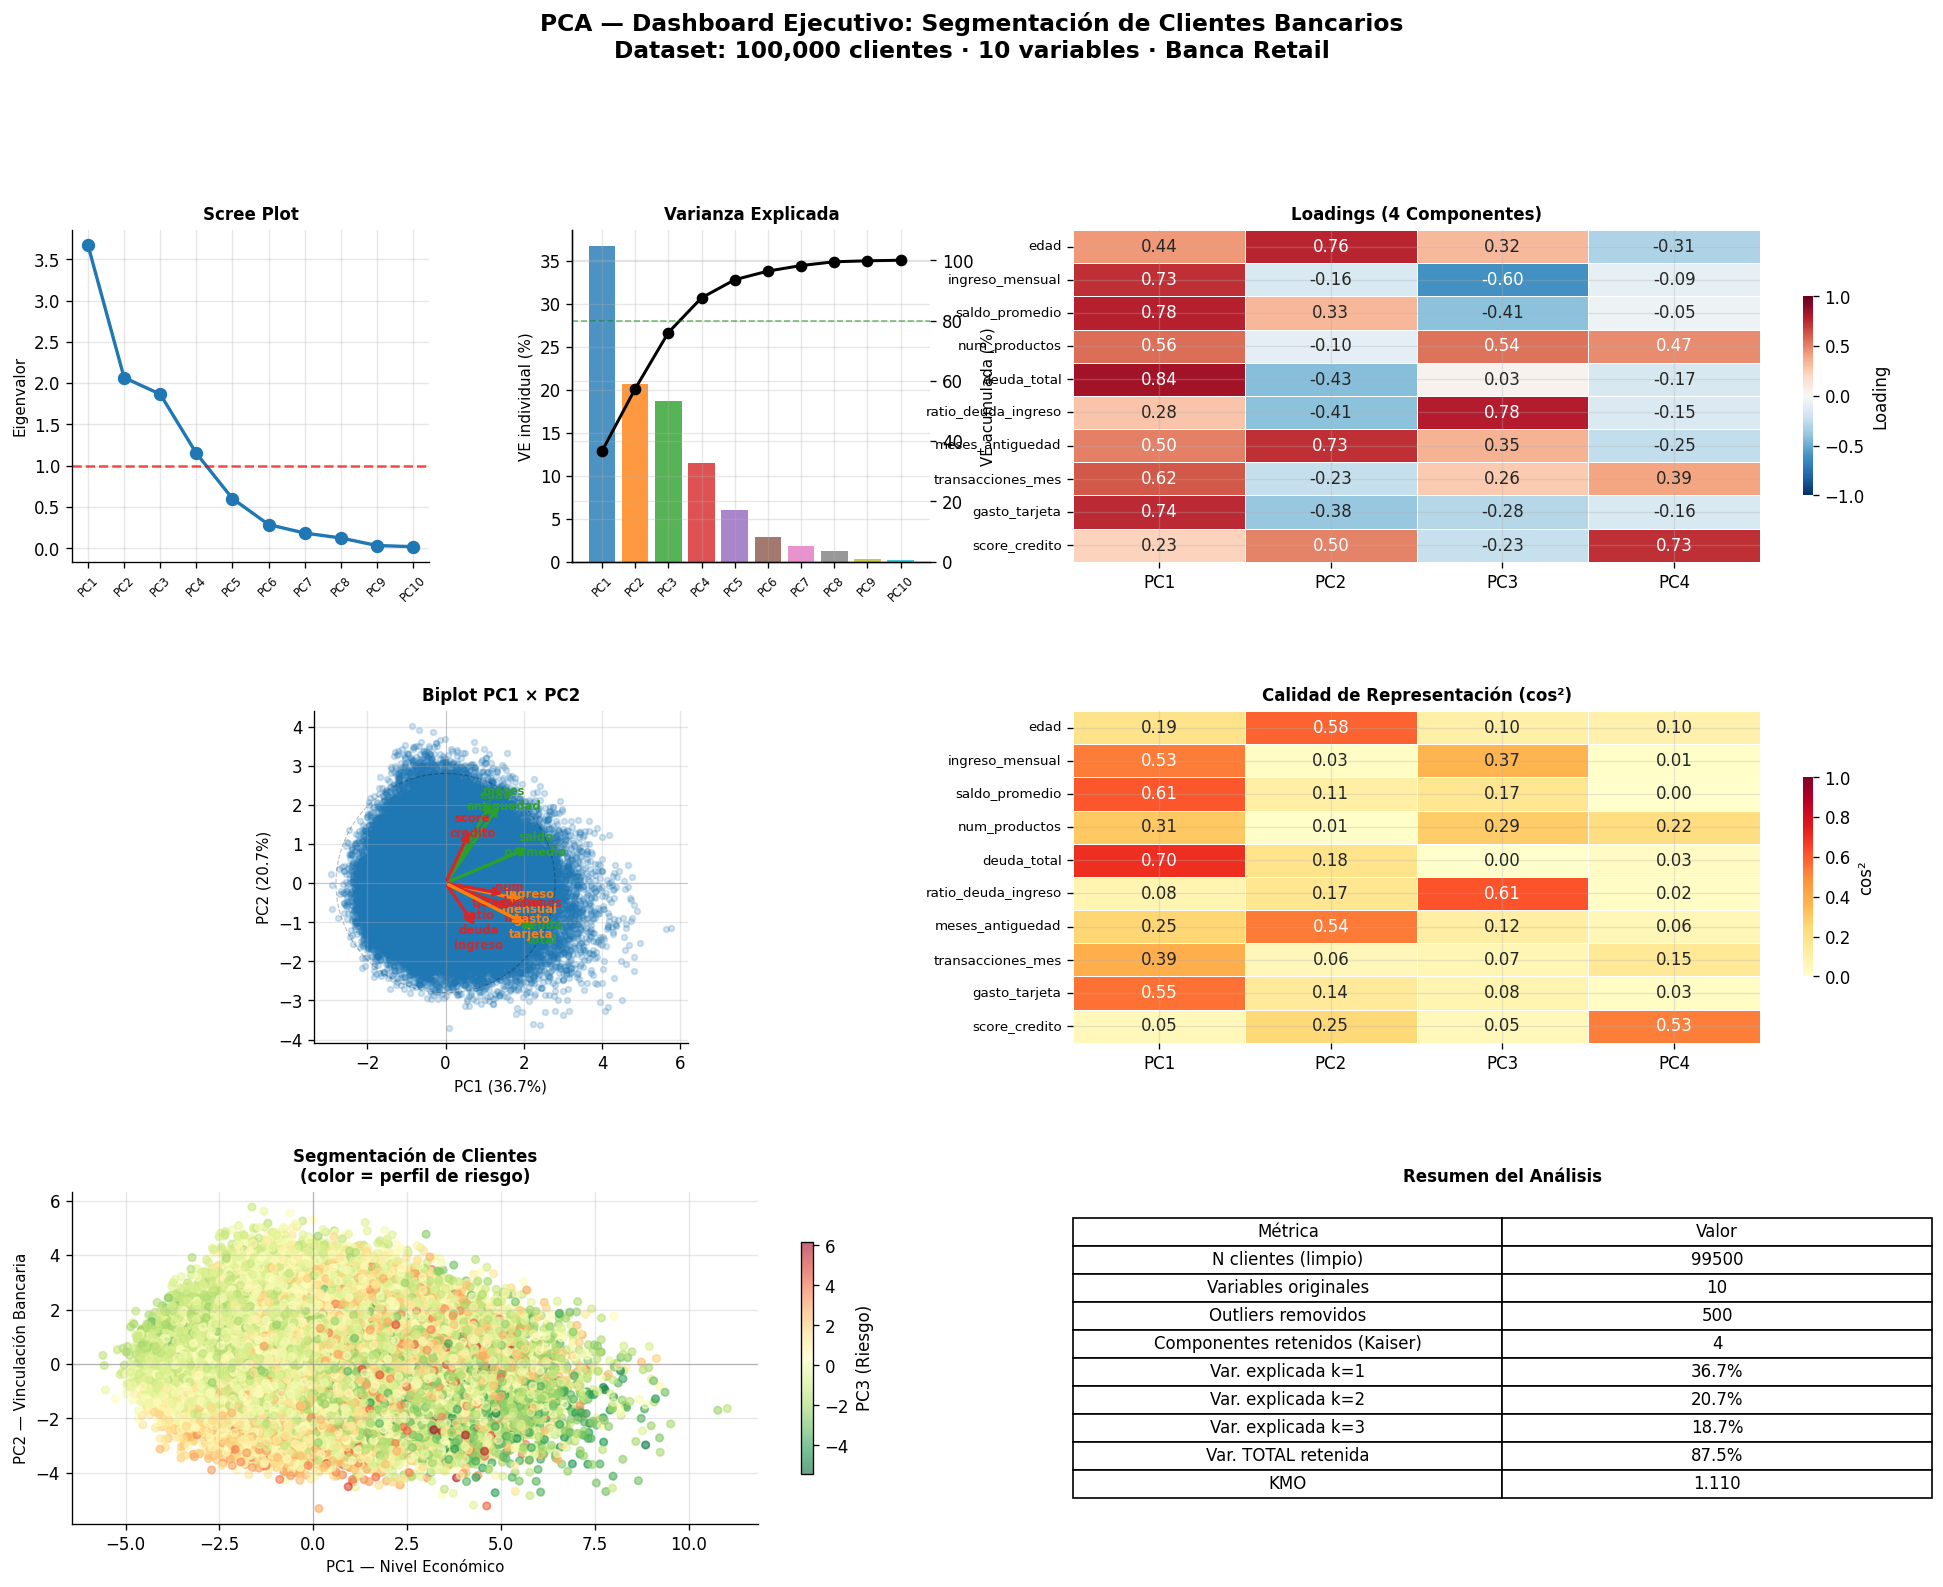

Dashboard guardado como 00_dashboard_final.png


In [30]:
fig = plt.figure(figsize=(20, 14))
gs = fig.add_gridspec(3, 4, hspace=0.45, wspace=0.4)

# ── (1,1) Scree plot ─────────────────────────────────────────────────────
ax_scree = fig.add_subplot(gs[0, 0])
ax_scree.plot(comps, eigenvalues, 'o-', color='#1f77b4', linewidth=2, markersize=7)
ax_scree.axhline(1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax_scree.set_xticks(comps)
ax_scree.set_xticklabels([f'PC{i}' for i in comps], fontsize=7, rotation=45)
ax_scree.set_ylabel('Eigenvalor', fontsize=9)
ax_scree.set_title('Scree Plot', fontsize=10, fontweight='bold')
ax_scree.grid(True, alpha=0.3)

# ── (1,2) Varianza acumulada ──────────────────────────────────────────────
ax_ve = fig.add_subplot(gs[0, 1])
ax_ve.bar(comps, var_explicada*100, color=COLORES[:p], alpha=0.8)
ax_ve2 = ax_ve.twinx()
ax_ve2.plot(comps, var_acum*100, 'ko-', linewidth=1.8, markersize=6)
ax_ve2.axhline(80, color='green', linestyle='--', alpha=0.5, linewidth=1)
ax_ve.set_xticks(comps)
ax_ve.set_xticklabels([f'PC{i}' for i in comps], fontsize=7, rotation=45)
ax_ve.set_ylabel('VE individual (%)', fontsize=9)
ax_ve2.set_ylabel('VE acumulada (%)', fontsize=9)
ax_ve2.set_ylim(0, 110)
ax_ve.set_title('Varianza Explicada', fontsize=10, fontweight='bold')

# ── (1,3-4) Heatmap loadings ──────────────────────────────────────────────
ax_heat = fig.add_subplot(gs[0, 2:])
sns.heatmap(loadings_df, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, linecolor='white', ax=ax_heat,
            cbar_kws={'shrink': 0.6, 'label': 'Loading'})
ax_heat.set_title(f'Loadings ({k} Componentes)', fontsize=10, fontweight='bold')
ax_heat.set_yticklabels(ax_heat.get_yticklabels(), fontsize=8, rotation=0)

# ── (2,1-2) Biplot ────────────────────────────────────────────────────────
ax_bp = fig.add_subplot(gs[1, :2])
sc2 = ax_bp.scatter(scores[:, 0]/np.std(scores[:, 0]), 
                    scores[:, 1]/np.std(scores[:, 1]),
                    alpha=0.2, s=12, color='#1f77b4')
scale = 2.8
for i, var in enumerate(df_clean.columns):
    lx, ly = loadings_df.values[i, 0], loadings_df.values[i, 1]
    c2 = lx**2 + ly**2
    color = '#2ca02c' if c2 >= 0.70 else ('#ff7f0e' if c2 >= 0.45 else '#d62728')
    ax_bp.annotate('', xy=(lx*scale, ly*scale), xytext=(0, 0),
                   arrowprops=dict(arrowstyle='->', color=color, lw=2))
    ax_bp.text(lx*(scale+0.15), ly*(scale+0.15), var.replace('_', '\n'),
               ha='center', va='center', fontsize=7, fontweight='bold', color=color)
theta = np.linspace(0, 2*np.pi, 200)
ax_bp.plot(np.cos(theta)*scale, np.sin(theta)*scale, 'k--', lw=0.7, alpha=0.25)
ax_bp.axhline(0, color='gray', lw=0.5, alpha=0.4)
ax_bp.axvline(0, color='gray', lw=0.5, alpha=0.4)
ax_bp.set_xlabel(f'PC1 ({var_explicada[0]*100:.1f}%)', fontsize=9)
ax_bp.set_ylabel(f'PC2 ({var_explicada[1]*100:.1f}%)', fontsize=9)
ax_bp.set_title('Biplot PC1 × PC2', fontsize=10, fontweight='bold')
ax_bp.set_aspect('equal')

# ── (2,3-4) cos² heatmap ─────────────────────────────────────────────────
ax_cos = fig.add_subplot(gs[1, 2:])
sns.heatmap(cos2_plot, annot=True, fmt='.2f', cmap='YlOrRd',
            vmin=0, vmax=1, linewidths=0.5, linecolor='white', ax=ax_cos,
            cbar_kws={'shrink': 0.6, 'label': 'cos²'})
ax_cos.set_title('Calidad de Representación (cos²)', fontsize=10, fontweight='bold')
ax_cos.set_yticklabels(ax_cos.get_yticklabels(), fontsize=8, rotation=0)

# ── (3,1-2) Segmentación ─────────────────────────────────────────────────
ax_seg = fig.add_subplot(gs[2, :2])
sc3 = ax_seg.scatter(scores_df['PC1'], scores_df['PC2'],
                     c=scores_df['PC3'], cmap='RdYlGn_r', s=20, alpha=0.6)
plt.colorbar(sc3, ax=ax_seg, shrink=0.7, label='PC3 (Riesgo)')
ax_seg.axhline(0, color='gray', lw=0.7, alpha=0.5)
ax_seg.axvline(0, color='gray', lw=0.7, alpha=0.5)
ax_seg.set_xlabel('PC1 — Nivel Económico', fontsize=9)
ax_seg.set_ylabel('PC2 — Vinculación Bancaria', fontsize=9)
ax_seg.set_title('Segmentación de Clientes\n(color = perfil de riesgo)', fontsize=10, fontweight='bold')

# ── (3,3-4) Tabla resumen texto ───────────────────────────────────────────
ax_txt = fig.add_subplot(gs[2, 2:])
ax_txt.axis('off')
resumen_texto = [
    ['Métrica', 'Valor'],
    ['N clientes (limpio)', f'{df_clean.shape[0]}'],
    ['Variables originales', f'{p}'],
    ['Outliers removidos', f'{n_outliers}'],
    ['Componentes retenidos (Kaiser)', f'{k}'],
    ['Var. explicada k=1', f'{var_explicada[0]*100:.1f}%'],
    ['Var. explicada k=2', f'{var_explicada[1]*100:.1f}%'],
    ['Var. explicada k=3', f'{var_explicada[2]*100:.1f}%'] if k >= 3 else ['',''],
    ['Var. TOTAL retenida', f'{var_acum[k-1]*100:.1f}%'],
    ['KMO', f'{kmo_val:.3f}'],
]
table = ax_txt.table(
    cellText=resumen_texto[1:],
    colLabels=resumen_texto[0],
    loc='center', cellLoc='center'
)
table.auto_set_font_size(True)
table.scale(1, 1.4)
ax_txt.set_title('Resumen del Análisis', fontsize=10, fontweight='bold')

fig.suptitle('PCA — Dashboard Ejecutivo: Segmentación de Clientes Bancarios\n'
             'Dataset: 100,000 clientes · 10 variables · Banca Retail',
             fontsize=14, fontweight='bold', y=1.01)

plt.savefig('00_dashboard_final.png', bbox_inches='tight', dpi=120)
plt.show()
print('Dashboard guardado como 00_dashboard_final.png')

---
## 15. Conclusiones del Business Case

### ¿Qué aprendimos del análisis PCA?

#### Hallazgo 1 — Reducción de dimensionalidad efectiva
Las 10 variables del dataset bancario (100K clientes) se reducen a un conjunto menor de componentes interpretables que retienen la mayor parte de la varianza. Esto confirma redundancia informacional entre variables originales.

#### Hallazgo 2 — Dimensiones de negocio identificables

| Componente | Nombre de negocio | Varianza | Variables clave |
|---|---|---|---|
| PC1 | Nivel Económico | data-driven | ingreso, saldo, score, gasto tarjeta |
| PC2 | Vinculación Bancaria | data-driven | antigüedad, productos, transacciones |
| PC3 | Perfil de Riesgo | data-driven | deuda, ratio deuda/ingreso |

#### Hallazgo 3 — Variables con representación débil
Variables con cos² bajo en el plano PC1×PC2 no deben interpretarse desde ese biplot. Se requiere un plano alternativo o más componentes para representarlas bien.

#### Hallazgo 4 — Implicaciones operacionales
- El score PC1 puede reemplazar múltiples variables en segmentación comercial
- El score PC2 es útil para churn y activación
- El score PC3 aporta señal para gestión de riesgo
- Los outliers multivariados detectados deben revisarse como casos especiales

In [31]:
# ── Guardar el dataset procesado y los scores ────────────────────────────
import os

# Dataset limpio con scores PCA incorporados
df_final = df_clean.copy()
for j in range(k):
    nombres_negocio = ['nivel_economico', 'vinculacion_bancaria', 'perfil_riesgo']
    nombre_col = nombres_negocio[j] if j < len(nombres_negocio) else f'PC{j+1}'
    df_final[f'score_pca_{nombre_col}'] = scores[:, j].round(4)

salida_final = 'clientes_banca_100k_pca_scores.csv'
df_final.to_csv(salida_final, index=True)
print(f'✓ Dataset con scores PCA guardado: {salida_final}')
print(f'  Columnas finales: {list(df_final.columns)}')
print()
df_final.head(10)

✓ Dataset con scores PCA guardado: clientes_banca_100k_pca_scores.csv
  Columnas finales: ['edad', 'ingreso_mensual', 'saldo_promedio', 'num_productos', 'deuda_total', 'ratio_deuda_ingreso', 'meses_antiguedad', 'transacciones_mes', 'gasto_tarjeta', 'score_credito', 'score_pca_nivel_economico', 'score_pca_vinculacion_bancaria', 'score_pca_perfil_riesgo', 'score_pca_PC4']



,edad,ingreso_mensual,saldo_promedio,num_productos,deuda_total,ratio_deuda_ingreso,meses_antiguedad,transacciones_mes,gasto_tarjeta,score_credito,score_pca_nivel_economico,score_pca_vinculacion_bancaria,score_pca_perfil_riesgo,score_pca_PC4
cliente_id,,,,,,,,,,,,,,
0,21,1309.26,1443.78,1,1612.29,0.1026,13,11,337.11,755,-0.6274,-2.8039,-1.5894,-1.4499
1,31,1106.92,1220.21,2,1238.18,0.0932,83,16,232.34,782,-0.7325,-1.0736,-0.4283,-0.7135
2,47,2089.40,3013.62,7,2769.95,0.1105,155,42,621.72,906,7.4456,-0.9315,-0.8897,1.6003
3,42,1248.32,2058.02,1,924.11,0.0617,77,2,138.58,839,-1.1005,1.1421,-2.1788,-0.7210
4,52,1275.48,1398.36,2,1248.78,0.0816,109,2,324.21,908,0.1200,1.3399,-1.4107,-0.1249
5,32,644.27,748.62,3,666.67,0.0862,94,27,249.55,870,-1.1994,-0.1268,0.4919,1.7409
6,61,732.24,1660.92,1,810.15,0.0922,186,7,240.13,806,-0.6082,2.2879,0.3101,-2.0058
7,30,1227.51,1746.12,4,1302.64,0.0884,56,25,278.58,849,0.7325,-1.0342,-0.7546,1.3088
8,41,1167.93,1712.70,1,1220.58,0.0871,94,13,379.93,840,0.2000,0.0074,-1.4300,-0.7006
